In [1]:
# CONFIGURATION
device = "Halle_1"
# selected_model = "GradientBoosting"
selected_model = "RandomForest"
test_placement = "middle"                # Options: 'start', 'middle', 'end', 'monthly'
skip_training = False

# After the first full run, change `device` and rerun from SELECT CURRENT DEVICE onward.

In [2]:
# IMPORT ALL DATA
import os
import pandas as pd

base_path = "../PreprocessedFiles/"
target_file_name = "combined_data_all_files.csv"

device_data = {}  # dictionary to store dataframes per device

# os.walk recursively traverses the directory tree
for root, dirs, files in os.walk(base_path):
    if target_file_name in files:
        # Use the name of the folder where the file was found as the device key
        device_name = os.path.basename(root)
        file_path = os.path.join(root, target_file_name)

        # Load the single file
        device_data[device_name] = pd.read_csv(file_path)
        print(f"Loaded: {device_name}")

# Print results
for name, df in device_data.items():
    print(f"\nDevice: {name}")
    print(df.info())

Loaded: Halle_1
Loaded: Halle_2
Loaded: Ukkel_1
Loaded: Ukkel_2
Loaded: Ukkel_3

Device: Halle_1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261622 entries, 0 to 261621
Data columns (total 23 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        261622 non-null  int64  
 1   CO2(ppm)          261622 non-null  int64  
 2   T_SCD40(*C)       261622 non-null  float64
 3   H_SCD40(%RH)      261622 non-null  float64
 4   Lux               261622 non-null  float64
 5   UVA               261622 non-null  float64
 6   UVB               261622 non-null  float64
 7   UVC               261622 non-null  float64
 8   BME68X_TEMP(*C)   261622 non-null  float64
 9   BME68X_HUM(%RH)   261622 non-null  float64
 10  BME68X_PRES(hPa)  261622 non-null  float64
 11  BME68X_VOC(kOhm)  261622 non-null  float64
 12  PM1.0_AVG_PPM     261622 non-null  float64
 13  PM1.0_PEAK_PPM    261622 non-null  float64
 14  PM2.5_AVG_PPM     2

In [3]:
# INITIALIZE DRIFT RESULTS MANAGER
# Keep this instance alive while switching devices; matching device/target/fault results are replaced in memory.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.base import clone
import matplotlib.ticker as mticker
import joblib
import os
import re
import itertools

class DriftResultsManager:
    COLUMNS = ["Device", "Target", "Fault_Sensor", "Model", "TPR", "FPR_Healthy", "Test_Placement", "Model_Train_Fraction", "Detector_Tune_Fraction", "Evaluation_Fraction"]

    def __init__(self, metrics_df=None):
        self.metrics_df = pd.DataFrame(columns=self.COLUMNS) if metrics_df is None else metrics_df.copy()
        for column in self.COLUMNS:
            if column not in self.metrics_df.columns:
                self.metrics_df[column] = np.nan
        self.metrics_df = self.metrics_df[self.COLUMNS]

    def add_result(self, device_name, target, fault_sensor, model_name, metrics, placement, train_fraction, tune_fraction, eval_fraction):
        """Insert or replace one held-out device/target/fault evaluation."""
        key = ((self.metrics_df["Device"] == device_name) & (self.metrics_df["Target"] == target) & (self.metrics_df["Fault_Sensor"] == fault_sensor) & (self.metrics_df["Model"] == model_name))
        self.metrics_df = self.metrics_df.loc[~key].copy()
        row = {"Device": device_name, "Target": target, "Fault_Sensor": fault_sensor, "Model": model_name, "TPR": metrics["TPR_faulty"], "FPR_Healthy": metrics["FPR_healthy"], "Test_Placement": placement, "Model_Train_Fraction": train_fraction, "Detector_Tune_Fraction": tune_fraction, "Evaluation_Fraction": eval_fraction}
        self.metrics_df = pd.concat([self.metrics_df, pd.DataFrame([row])], ignore_index=True)

    def get_split_config(self, device_name, target, model_name):
        """Return the split used to train/evaluate a detector, preferring its self-fault row."""
        rows = self.metrics_df[(self.metrics_df["Device"] == device_name) & (self.metrics_df["Target"] == target) & (self.metrics_df["Model"] == model_name)]
        if rows.empty:
            return {}
        self_fault_rows = rows[rows["Fault_Sensor"] == rows["Target"]]
        row = (self_fault_rows if not self_fault_rows.empty else rows).iloc[-1]
        return {"test_placement": row["Test_Placement"], "model_train_fraction": float(row["Model_Train_Fraction"]), "detector_tune_fraction": float(row["Detector_Tune_Fraction"]), "evaluation_fraction": float(row["Evaluation_Fraction"])}

    def save(self, path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        joblib.dump(self.metrics_df, path)

    @classmethod
    def load(cls, path):
        if not os.path.exists(path):
            return cls()
        loaded = joblib.load(path)
        if isinstance(loaded, pd.DataFrame):
            return cls(loaded)
        if hasattr(loaded, "metrics_df"):
            return cls(loaded.metrics_df)
        raise TypeError(f"Unsupported drift results file contents: {type(loaded).__name__}")


results_manager_path = "../results/drift_results_manager_final.pkl"
drift_results_manager = DriftResultsManager()
print("Initialized an empty drift results manager.")

Initialized an empty drift results manager.


In [4]:
# DATA PREPROCESSING
import re
import numpy as np

columns_to_drop = [
    "UTC_STEP", "TIME_SEC_STEP", "TIME_SEC", "GPS_TIMESTAMP", "DATE_DT", "NO2_measured(mV)", "NO2_vref(mV)", "Ozon_measured(mV)", "Ozon_vref(mV)", "CO_vref(mV)", "CO_measured(mV)", "ACC_X(m/s2)", "ACC_Y(m/s2)",
    "ACC_Z(m/s2)", "SYS_MILLIS_TIME (ms)", "TIME", "DATE", "GPS_NSATS", "GPS_ALT(m)", "GPS_LON", "GPS_LAT","GPS_FIX", "PM_N_NAN", "PM_N_OBSTRUCTIONS", "PM_N_SUCCESS", "Unnamed: 0", "MIC(dBSPL)", "BATTERY_VOLT","BATTERY_PERCENT"
]


def clean_name(name):
    name = re.sub(r'[*()%\s]+', '_', name)  # Replace sequences of symbols with a single _
    return name.strip('_')  # Remove trailing/leading underscores


def preprocess(key, df):
    df = df.copy()
    df.drop(columns=columns_to_drop, inplace=True, errors="ignore")

    df['UTC_TIMESTAMP'] = pd.to_datetime(df['UTC_TIMESTAMP'], utc=True, errors='coerce')
    if key == "Halle_1":
        # valid_mask = (df['UTC_TIMESTAMP'] <= '2026-01-14') | (df['UTC_TIMESTAMP'] >= '2026-03-01')  # exclude data where O3 sensor was faulty
        # df = df[valid_mask]
        # df = df[df['UTC_TIMESTAMP'] <= '2026-03-01']  # optional: exclude summer data
        df = df[df['UTC_TIMESTAMP'] >= '2026-03-29']  # optional: exclude winter data
    elif key == "Halle_2":
        # df = df[df['UTC_TIMESTAMP'] <= '2026-03-01']  # optional: exclude summer data
        df = df[df['UTC_TIMESTAMP'] >= '2026-03-29']  # optional: exclude winter data

    start_date = pd.Timestamp("2025-12-01", tz="UTC")
    end_date = pd.Timestamp("2026-12-31", tz="UTC")
    df = df[(df['UTC_TIMESTAMP'] >= start_date) & (df['UTC_TIMESTAMP'] <= end_date)]
    df = df.dropna(subset=['UTC_TIMESTAMP']).sort_values('UTC_TIMESTAMP')
    df.columns = [clean_name(column) for column in df.columns]

    df['Hour'] = df['UTC_TIMESTAMP'].dt.hour
    df['Month'] = df['UTC_TIMESTAMP'].dt.month
    df['Hour_sin'] = np.sin(2 * np.pi * df['Hour']/24)
    df['Hour_cos'] = np.cos(2 * np.pi * df['Hour']/24)
    df['Month_sin'] = np.sin(2 * np.pi * df['Month']/12)
    df['Month_cos'] = np.cos(2 * np.pi * df['Month']/12)
    df.drop(columns=['Hour', 'Month'], inplace=True)

    numeric_columns = df.select_dtypes(include=[np.number]).columns
    df[numeric_columns] = df[numeric_columns].replace([np.inf, -np.inf], np.nan)
    return df


# Preprocess every loaded device once.
for key in device_data:
    print(f"Device {key}: Before preprocessing rows = {len(device_data[key])}")
    device_data[key] = preprocess(key, device_data[key])
    print(f"Device {key}: After preprocessing rows = {len(device_data[key])}\n")

Device Halle_1: Before preprocessing rows = 261622
Device Halle_1: After preprocessing rows = 90676

Device Halle_2: Before preprocessing rows = 437807
Device Halle_2: After preprocessing rows = 86724

Device Ukkel_1: Before preprocessing rows = 82793
Device Ukkel_1: After preprocessing rows = 82793

Device Ukkel_2: Before preprocessing rows = 107034
Device Ukkel_2: After preprocessing rows = 107034

Device Ukkel_3: Before preprocessing rows = 350151
Device Ukkel_3: After preprocessing rows = 350151



In [5]:
# DEFINE MODEL PIPELINES AND HELPER FUNCTIONS
base_models = {
    'Linear': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', LinearRegression())
    ]),
    'ElasticNet': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000))
    ]),
    'RandomForest': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', RandomForestRegressor(n_estimators=100, max_depth=24, n_jobs=-1, random_state=42))
    ]),
    'GradientBoosting': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', GradientBoostingRegressor(random_state=42))
    ])
}

print("Models initialized and ready for training.")


# Functions to induce faults
def induce_bias(series, bias_value, start_index):
    """Adds a constant offset to the signal from start_index onwards."""
    corrupted = series.copy()
    corrupted.iloc[start_index:] = series.iloc[start_index:] + bias_value
    return corrupted

def induce_drift(series, drift_total, start_index):
    """Adds a linearly increasing error from 0 to drift_total starting at start_index."""
    corrupted = series.copy()
    n_affected = len(series) - start_index
    drift_steps = np.linspace(0, drift_total, n_affected)
    corrupted.iloc[start_index:] = series.iloc[start_index:] + drift_steps
    return corrupted

def induce_scaling(series, scale_factor, start_index):
    """Multiplies the signal by a gain factor from start_index onwards."""
    corrupted = series.copy()
    corrupted.iloc[start_index:] = series.iloc[start_index:] * scale_factor
    return corrupted

def induce_hard_fault(series, fault_value, start_index):
    """Forces the signal to a constant value (default 0) from start_index onwards."""
    corrupted = series.copy()
    corrupted.iloc[start_index:] = fault_value
    return corrupted


# Time-series plotting function
def plot_diagnostic_grid(target, model_name, t_test, y_actual, y_pred, raw_res, z_res, fault_sensor=None, fault_time=None):
    """Plot actual/predicted values, raw residuals, and standardized residuals."""
    fig, axes = plt.subplots(1, 2, figsize=(32, 4))

    mode_str = f"(Drift Injected in {fault_sensor})" if fault_sensor is not None else "(Baseline)"
    fig.suptitle(f"Target: {target} {mode_str}", fontsize=18, fontweight="bold", y=1.05)

    # Panel 1: Actual vs predicted
    axes[0].plot(t_test, y_actual, label="Actual", alpha=0.5)
    axes[0].plot(t_test, y_pred, label="Predicted", alpha=0.7, linestyle="--")
    if fault_time is not None:
        axes[0].axvline(fault_time, color="red", linestyle="--", alpha=0.6, label="Fault Injection")
    axes[0].set_title("Actual vs Predicted")
    axes[0].legend()

    # Panel 2: Raw residuals
    # axes[1].axhline(0, color="black", linewidth=1)
    # axes[1].plot(t_test, raw_res, alpha=0.3, color="gray")
    # axes[1].plot(t_test, pd.Series(raw_res).rolling(500).mean(), color="red", label="Rolling Mean (500)")
    # if fault_time is not None:
    #     axes[1].axvline(fault_time, color="red", linestyle="--", alpha=0.6, label="Fault Injection")
    # axes[1].set_title("Raw Residuals")
    # axes[1].legend()

    # Panel 3: Standardized residuals
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].axhline(3, color="red", linestyle=":", alpha=0.4, label="±3 Threshold")
    axes[1].axhline(-3, color="red", linestyle=":", alpha=0.4)
    axes[1].plot(t_test, z_res, alpha=0.2, color="gray")
    z_line_color = "blue" if fault_time is None else "darkblue"
    axes[1].plot(t_test, pd.Series(z_res).rolling(500).mean(), color=z_line_color, label="Rolling Z-Bias")
    if fault_time is not None:
        axes[1].axvline(fault_time, color="red", linestyle="--", alpha=0.6, label="Fault Injection")
    axes[1].set_title("Standardized Residuals (Z-Score)")
    axes[1].set_ylabel("Std Deviations")
    axes[1].legend()

    for ax in axes:
        ax.xaxis.set_major_locator(mticker.MaxNLocator(6))
        ax.grid(True, alpha=0.2)

    plt.tight_layout()
    plt.show()

# Data preparation - train/tune/evaluate split
def prepare_target_data(target, placement=None, model_train_fraction_value=None, detector_tune_fraction_value=None, evaluation_fraction_value=None):
    """
    Create disjoint model-training, detector-tuning, and held-out evaluation sets.

    The default split is 60% / 20% / 20%. The detector rule is optimized only on the tuning set; 
    final TPR, FPR, and delay are calculated on the held-out evaluation set.
    """
    if target not in df_numeric_clean.columns:
        raise KeyError(f"{target!r} is not present in df_numeric_clean.")

    placement = test_placement if placement is None else placement.lower()
    train_fraction_value = model_train_fraction if model_train_fraction_value is None else float(model_train_fraction_value)
    tune_fraction_value = detector_tune_fraction if detector_tune_fraction_value is None else float(detector_tune_fraction_value)
    eval_fraction_value = evaluation_fraction if evaluation_fraction_value is None else float(evaluation_fraction_value)

    valid_placements = {"start", "middle", "end", "monthly"}
    if placement not in valid_placements:
        raise ValueError(f"placement must be one of {sorted(valid_placements)}, received {placement!r}.")
    if any(value <= 0 or value >= 1 for value in (train_fraction_value, tune_fraction_value, eval_fraction_value)):
        raise ValueError("All split fractions must lie strictly between 0 and 1.")
    if not np.isclose(train_fraction_value + tune_fraction_value + eval_fraction_value, 1.0):
        raise ValueError("Model-training, detector-tuning, and evaluation fractions must sum to 1.0.")

    df_clean = df_numeric_clean.dropna(subset=[target]).copy().ffill().bfill()

    cols_to_drop = [target]
    if target == "PM1.0_AVG_PPM":
        cols_to_drop.append("PM1.0_PEAK_PPM")
    elif target == "PM2.5_AVG_PPM":
        cols_to_drop.append("PM2.5_PEAK_PPM")
    elif target == "PM10.0_AVG_PPM":
        cols_to_drop.append("PM10.0_PEAK_PPM")

    X = df_clean.drop(columns=[column for column in cols_to_drop if column in df_clean.columns])
    y = df_clean[target]
    timestamps = pd.to_datetime(df.loc[df_clean.index, "UTC_TIMESTAMP"], errors="coerce")

    if timestamps.isna().any():
        raise ValueError(f"{int(timestamps.isna().sum())} rows have invalid UTC_TIMESTAMP values.")
    if len(df_clean) < 5:
        raise ValueError(f"Not enough valid rows to create a 60/20/20 split for target {target!r}.")

    total_len = len(df_clean)
    n_train = int(total_len * train_fraction_value)
    n_tune = int(total_len * tune_fraction_value)
    n_eval = total_len - n_train - n_tune

    if min(n_train, n_tune, n_eval) < 1:
        raise ValueError(f"The requested fractions produce an empty partition for target {target!r}.")

    if placement == "end":
        train_idx = np.arange(0, n_train)
        tune_idx = np.arange(n_train, n_train + n_tune)
        eval_idx = np.arange(n_train + n_tune, total_len)

    elif placement == "start":
        eval_idx = np.arange(0, n_eval)
        tune_idx = np.arange(n_eval, n_eval + n_tune)
        train_idx = np.arange(n_eval + n_tune, total_len)

    elif placement == "middle":
        eval_start = int((total_len - n_eval) * 0.4)
        eval_end = eval_start + n_eval
        eval_idx = np.arange(eval_start, eval_end)

        remaining_idx = np.concatenate([np.arange(0, eval_start), np.arange(eval_end, total_len)])
        tune_idx = remaining_idx[-n_tune:]
        train_idx = remaining_idx[:-n_tune]

    else:  # monthly
        train_idx, tune_idx, eval_idx = [], [], []
        month_keys = timestamps.dt.strftime("%Y-%m").to_numpy()

        for month in pd.unique(month_keys):
            month_idx = np.flatnonzero(month_keys == month)
            month_train = int(len(month_idx) * train_fraction_value)
            month_tune = int(len(month_idx) * tune_fraction_value)
            month_eval = len(month_idx) - month_train - month_tune

            # Very short months cannot support three disjoint partitions.
            # Retain those rows for model training rather than leaking them.
            if min(month_train, month_tune, month_eval) < 1:
                train_idx.extend(month_idx)
                continue

            train_idx.extend(month_idx[:month_train])
            tune_idx.extend(month_idx[month_train:month_train + month_tune])
            eval_idx.extend(month_idx[month_train + month_tune:])

        train_idx = np.asarray(sorted(train_idx), dtype=int)
        tune_idx = np.asarray(sorted(tune_idx), dtype=int)
        eval_idx = np.asarray(sorted(eval_idx), dtype=int)

        if min(len(train_idx), len(tune_idx), len(eval_idx)) < 1:
            raise ValueError("The monthly 60/20/20 split produced an empty partition.")

    X_train, y_train = X.iloc[train_idx].copy(), y.iloc[train_idx].copy()
    X_tune, y_tune, t_tune = X.iloc[tune_idx].copy(), y.iloc[tune_idx].copy(), timestamps.iloc[tune_idx].copy()
    X_eval, y_eval, t_eval = X.iloc[eval_idx].copy(), y.iloc[eval_idx].copy(), timestamps.iloc[eval_idx].copy()

    tune_start_index = min(max(int(len(X_tune) * fault_start_fraction), 0), len(X_tune) - 1)
    eval_start_index = min(max(int(len(X_eval) * fault_start_fraction), 0), len(X_eval) - 1)
    tune_fault_time = t_tune.iloc[tune_start_index]
    eval_fault_time = t_eval.iloc[eval_start_index]

    return (
        X_train,
        y_train,
        X_tune,
        y_tune,
        t_tune,
        tune_start_index,
        tune_fault_time,
        X_eval,
        y_eval,
        t_eval,
        eval_start_index,
        eval_fault_time,
    )

Models initialized and ready for training.


In [6]:
# SELECT CURRENT DEVICE
if device not in device_data:
    raise KeyError(f"Unknown device {device!r}. Available devices: {sorted(device_data)}")

df = device_data[device]
df_numeric_clean = df.select_dtypes(include=[np.number]).copy()

model_train_fraction = 0.60
detector_tune_fraction = 0.20
evaluation_fraction = 0.20
fault_start_fraction = 0.30

# Directory setup for the selected device
model_dir = f"../saved_models_noref/{device}/"
model_dir_temp = f"../saved_models_noref_temp/{device}/"
os.makedirs(model_dir, exist_ok=True)
os.makedirs(model_dir_temp, exist_ok=True)


def calculate_drift_amounts(range_fraction=0.25):
    """Return per-target drift amounts as a fraction of the evaluation-set 1st–99th percentile range."""
    target_columns = ["Lux", "UVA", "UVB", "UVC", "PM1.0_AVG_PPM", "T_SCD40_C", "BME68X_TEMP_C", "H_SCD40_RH", "BME68X_HUM_RH", "BME68X_PRES_hPa", "BME68X_VOC_kOhm", "CO_value_mV", "CO2_ppm"]
    drift_amounts = {}

    for target in target_columns:
        if target not in df_numeric_clean.columns:
            print(f"Skipping {target}: column not found.")
            continue

        _, _, _, _, _, _, _, _, y_eval, _, _, _ = prepare_target_data(target)
        values = y_eval.replace([np.inf, -np.inf], np.nan).dropna()

        if values.empty:
            print(f"Skipping {target}: no valid evaluation values.")
            continue

        lower = values.quantile(0.0001)
        upper = values.quantile(0.9999)
        healthy_range = upper - lower

        if not np.isfinite(healthy_range) or healthy_range <= 0:
            print(f"Skipping {target}: invalid evaluation 1st–99th percentile range: {healthy_range}")
            continue

        drift_amounts[target] = float(range_fraction * healthy_range)
        print(f"{target}: Q1={lower:.3f}, Q99={upper:.3f}, range={healthy_range:.3f}, drift={drift_amounts[target]:.3f}")

    return drift_amounts


drift_amounts = calculate_drift_amounts(0.25)
# drift_amounts = {"Lux": 5000, "UVA": 500, "UVB": 4, "UVC": 4, "PM1.0_AVG_PPM": 20, "T_SCD40_C": 10, "BME68X_TEMP_C": 10, "H_SCD40_RH": 20, "BME68X_HUM_RH": 20, "BME68X_PRES_hPa": 10, "BME68X_VOC_kOhm": 80, "CO_value_mV": 10, "CO2_ppm": 300}
# drift_amounts = {"Lux": 5000, "UVA": 500, "UVB": 4, "UVC": 4, "PM1.0_AVG_PPM": 20, "T_SCD40_C": 10, "BME68X_TEMP_C": 10, "H_SCD40_RH": 20, "BME68X_HUM_RH": 20, "BME68X_PRES_hPa": 10, "BME68X_VOC_kOhm": 80, "CO2_ppm": 300}
# drift_amounts = {"Lux": 5000, "PM1.0_AVG_PPM": 20, "T_SCD40_C": 10, "BME68X_TEMP_C": 10, "H_SCD40_RH": 20, "BME68X_HUM_RH": 20, "BME68X_PRES_hPa": 10, "BME68X_VOC_kOhm": 80, "CO2_ppm": 300}
# drift_amounts = {"CO2_ppm": 200}

print(f"Selected device: {device}")
print("Preprocessing complete. Columns:", df_numeric_clean.columns.tolist())
print("Selected Drift Values: ")
for target, amount in drift_amounts.items():
    print(f"{target}: {amount:.3f}")

Lux: Q1=0.000, Q99=4591.427, range=4591.427, drift=1147.857
UVA: Q1=0.000, Q99=387.262, range=387.262, drift=96.815
UVB: Q1=0.000, Q99=66.595, range=66.595, drift=16.649
UVC: Q1=0.000, Q99=17.057, range=17.057, drift=4.264
PM1.0_AVG_PPM: Q1=0.228, Q99=10.750, range=10.522, drift=2.631
T_SCD40_C: Q1=16.833, Q99=24.452, range=7.619, drift=1.905
BME68X_TEMP_C: Q1=18.988, Q99=26.582, range=7.594, drift=1.898
H_SCD40_RH: Q1=46.320, Q99=67.016, range=20.696, drift=5.174
BME68X_HUM_RH: Q1=41.201, Q99=62.680, range=21.479, drift=5.370
BME68X_PRES_hPa: Q1=1015.110, Q99=1018.540, range=3.430, drift=0.857
BME68X_VOC_kOhm: Q1=317.720, Q99=642.122, range=324.402, drift=81.100
CO_value_mV: Q1=-6.724, Q99=30.349, range=37.073, drift=9.268
CO2_ppm: Q1=367.881, Q99=566.000, range=198.119, drift=49.530
Selected device: Halle_1
Preprocessing complete. Columns: ['CO2_ppm', 'T_SCD40_C', 'H_SCD40_RH', 'Lux', 'UVA', 'UVB', 'UVC', 'BME68X_TEMP_C', 'BME68X_HUM_RH', 'BME68X_PRES_hPa', 'BME68X_VOC_kOhm', 'PM1.0_

In [7]:
# STATISTICAL TESTS DEFINITION

TEST_PARAM_GRID = {
    "zscore": [
        {"threshold": threshold}
        for threshold in [2.0, 2.5, 3.0, 3.5, 4.0]
    ],
    "cusum": [
        {"k": k, "h": h}
        for k, h in itertools.product(
            [0.25, 0.50, 0.75, 1.00],
            [3.0, 4.0, 5.0, 6.0, 8.0],
        )
    ],
    "ewma": [
        {"alpha": alpha, "limit_sigma": limit_sigma}
        for alpha, limit_sigma in itertools.product(
            [0.10, 0.15, 0.20, 0.25, 0.30],
            [2.0, 2.5, 3.0, 3.5],
        )
    ],
    "rolling": [
        {"window": window, "threshold": threshold}
        for window, threshold in itertools.product(
            [10, 20, 30, 50, 100],
            [2.0, 2.5, 3.0, 3.5, 4.0],
        )
    ],
}


# ================================
# STATISTICAL TESTS
# ================================
def zscore_detector(z, threshold=3.0):
    """Flag individual standardized residuals outside +/- threshold."""
    z = np.asarray(z, dtype=float)
    return (np.abs(z) > threshold).astype(int)


def cusum_detector(z, k=0.5, h=5.0):
    """Two-sided tabular CUSUM for persistent positive or negative mean shifts."""
    z = np.asarray(z, dtype=float)
    s_pos = np.zeros(len(z), dtype=float)
    s_neg = np.zeros(len(z), dtype=float)
    flags = np.zeros(len(z), dtype=int)

    for i in range(1, len(z)):
        s_pos[i] = max(0.0, s_pos[i - 1] + z[i] - k)
        s_neg[i] = min(0.0, s_neg[i - 1] + z[i] + k)
        flags[i] = int(s_pos[i] > h or abs(s_neg[i]) > h)

    return flags


def ewma_detector(z, alpha=0.2, limit_sigma=3.0):
    """
    EWMA control chart for gradual mean shifts.

    Because z is standardized, the asymptotic EWMA standard deviation is
    sqrt(alpha / (2 - alpha)). The alarm limit is expressed in multiples of
    that EWMA standard deviation rather than raw residual standard deviations.
    """
    z = np.asarray(z, dtype=float)
    ewma = np.zeros(len(z), dtype=float)
    flags = np.zeros(len(z), dtype=int)
    control_limit = limit_sigma * np.sqrt(alpha / (2.0 - alpha))

    for i in range(1, len(z)):
        ewma[i] = alpha * z[i] + (1.0 - alpha) * ewma[i - 1]
        flags[i] = int(abs(ewma[i]) > control_limit)

    return flags


def rolling_mean_detector(z, window=20, threshold=3.0):
    """
    Sliding-window mean-shift detector.

    The rolling mean is converted to a z-like statistic by multiplying it by
    sqrt(window). Under independent unit-variance residuals this expresses the
    local mean in standard-error units, making thresholds comparable across
    different window lengths.
    """
    z = np.asarray(z, dtype=float)
    flags = np.zeros(len(z), dtype=int)

    if window < 2:
        raise ValueError("window must be at least 2")
    if window >= len(z):
        return flags

    cumulative = np.concatenate(([0.0], np.cumsum(z)))
    for i in range(window, len(z)):
        rolling_mean = (cumulative[i] - cumulative[i - window]) / window
        rolling_stat = abs(rolling_mean) * np.sqrt(window)
        flags[i] = int(rolling_stat > threshold)

    return flags


TEST_REGISTRY = {
    "zscore": zscore_detector,
    "cusum": cusum_detector,
    "ewma": ewma_detector,
    "rolling": rolling_mean_detector,
}


# ================================
# TEST EXECUTION AND FUSION
# ================================
def run_statistical_tests(z_array, test_params):
    """Run every active statistical test with its target-specific parameters."""
    return {
        test_name: test_func(z_array, **test_params[test_name])
        for test_name, test_func in TEST_REGISTRY.items()
    }


def weighted_fuse_tests(test_flags_dict, weights, threshold):
    """Fuse binary test outputs using raw target-specific integer weights."""
    n_samples = len(next(iter(test_flags_dict.values())))
    weighted_score = np.zeros(n_samples, dtype=float)

    for test_name, flags in test_flags_dict.items():
        weighted_score += np.asarray(flags) * weights.get(test_name, 0.0)

    return (weighted_score >= threshold).astype(int)


def enforce_persistence(flags, min_run=15):
    """Retain only alarm runs containing at least min_run consecutive samples."""
    flags = np.asarray(flags, dtype=int)
    output = np.zeros_like(flags)
    run_start = None

    for i, flag in enumerate(flags):
        if flag and run_start is None:
            run_start = i
        elif not flag and run_start is not None:
            if i - run_start >= min_run:
                output[run_start:i] = 1
            run_start = None

    if run_start is not None and len(flags) - run_start >= min_run:
        output[run_start:] = 1

    return output


def apply_weights(tests_dict, weights, threshold=0.5, min_run=15):
    """Fuse the tests and apply the persistence rule."""
    total_weight = sum(weights.values())
    if total_weight <= 0:
        raise ValueError("At least one statistical-test weight must be positive.")
        
    fused_flags = weighted_fuse_tests(tests_dict, weights, threshold)
    return enforce_persistence(fused_flags, min_run=min_run)


# ================================
# METRICS AND SEARCH HELPERS
# ================================
def calculate_rates(flags, start_index, is_healthy=False):
    """Calculate TPR and FPR for healthy or fault-injected residuals."""
    flags = np.asarray(flags, dtype=int)

    if is_healthy:
        return 0.0, float(np.mean(flags))

    before_fault = flags[:start_index]
    after_fault = flags[start_index:]
    fpr = float(np.mean(before_fault)) if len(before_fault) else 0.0
    tpr = float(np.mean(after_fault)) if len(after_fault) else 0.0
    return tpr, fpr


def detection_delay(flags, start_index):
    """Return samples from fault onset to the first alarm, or NaN if absent."""
    detected = np.flatnonzero(np.asarray(flags)[start_index:] == 1)
    return int(detected[0]) if len(detected) else np.nan


def evaluate_flags(flags_healthy, flags_faulty, start_index, fpr_penalty=2.0, max_fpr=0.30):
    """Evaluate one detector configuration using the score objective."""
    _, healthy_fpr = calculate_rates(flags_healthy, start_index, is_healthy=True)
    faulty_tpr, faulty_fpr = calculate_rates(flags_faulty, start_index, is_healthy=False)

    score = faulty_tpr - fpr_penalty * healthy_fpr
    if healthy_fpr > max_fpr or faulty_fpr > max_fpr:
        score -= 100.0

    return {
        "score": score,
        "metrics": {
            "TPR_faulty": faulty_tpr,
            "FPR_faulty": faulty_fpr,
            "FPR_healthy": healthy_fpr,
            "delay": detection_delay(flags_faulty, start_index),
        },
    }


def _candidate_key(candidate):
    """Deterministic tie-breaking: score, TPR, FPR, then detection delay."""
    metrics = candidate["metrics"]
    delay = metrics["delay"]
    delay_key = -float(delay) if np.isfinite(delay) else -np.inf
    return (
        candidate["score"],
        metrics["TPR_faulty"],
        -metrics["FPR_healthy"],
        delay_key,
    )


def generate_weight_grid(test_names, weight_options=(0, 1, 2)):
    """Generate all non-zero integer weight combinations."""
    test_names = list(test_names)
    for combination in itertools.product(weight_options, repeat=len(test_names)):
        if sum(combination) == 0:
            continue
        yield dict(zip(test_names, combination))


# ===============================================
# TESTS AND RULE OPTIMIZATION
# ===============================================
def optimize_test_parameters(z_healthy, z_faulty, start_index, test_param_grid=TEST_PARAM_GRID, min_run=15, fpr_penalty=2.0, max_fpr=0.30):
    """
    Select the best parameter set independently for every statistical test.
    """
    best_params = {}
    search_summary = {}

    for test_name, test_func in TEST_REGISTRY.items():
        if test_name not in test_param_grid:
            raise KeyError(f"No parameter grid supplied for test {test_name!r}.")

        best_candidate = None
        for params in test_param_grid[test_name]:
            raw_healthy = test_func(z_healthy, **params)
            raw_faulty = test_func(z_faulty, **params)
            flags_healthy = enforce_persistence(raw_healthy, min_run=min_run)
            flags_faulty = enforce_persistence(raw_faulty, min_run=min_run)

            candidate = evaluate_flags(flags_healthy, flags_faulty, start_index, fpr_penalty=fpr_penalty, max_fpr=max_fpr)
            candidate["params"] = params.copy()

            if best_candidate is None or _candidate_key(candidate) > _candidate_key(best_candidate):
                best_candidate = candidate

        best_params[test_name] = best_candidate["params"]

    return best_params


def optimize_detector_rule(z_healthy, z_faulty, start_index, test_param_grid=TEST_PARAM_GRID, weight_options=(0, 1, 2), decision_threshold_options=(1, 2, 3, 4, 5, 6, 7, 8), min_run=15, fpr_penalty=2.0, max_fpr=0.30):
    """Optimize per-test parameters first, then optimize ensemble weights."""
    best_test_params = optimize_test_parameters(z_healthy, z_faulty, start_index, test_param_grid=test_param_grid, min_run=min_run, fpr_penalty=fpr_penalty, max_fpr=max_fpr)

    tests_healthy = run_statistical_tests(z_healthy, best_test_params)
    tests_faulty = run_statistical_tests(z_faulty, best_test_params)

    best_rule = None

    for weights in generate_weight_grid(TEST_REGISTRY.keys(), weight_options):
    
        for threshold in decision_threshold_options:

            if sum(weights.values()) < threshold:
                continue
            
            flags_healthy = apply_weights(tests_healthy, weights, threshold=threshold, min_run=min_run)
            flags_faulty = apply_weights(tests_faulty, weights, threshold=threshold, min_run=min_run)
    
            candidate = evaluate_flags(flags_healthy, flags_faulty, start_index, fpr_penalty=fpr_penalty, max_fpr=max_fpr)
    
            candidate.update({"weights": weights.copy(), "decision_threshold": threshold, "test_params": best_test_params, "flags_healthy": flags_healthy.copy(), "flags_faulty": flags_faulty.copy()})
    
            if (best_rule is None or _candidate_key(candidate) > _candidate_key(best_rule)):
                best_rule = candidate
    
    return best_rule



TRAINING TARGET: Lux


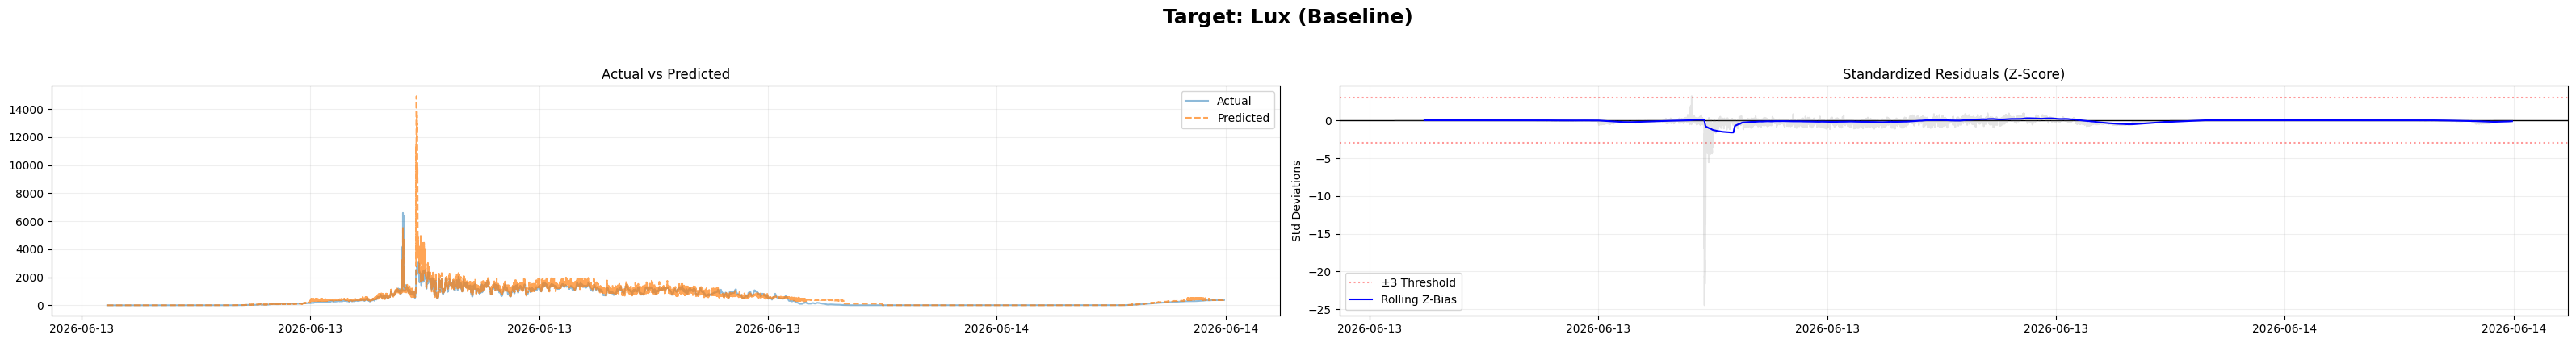

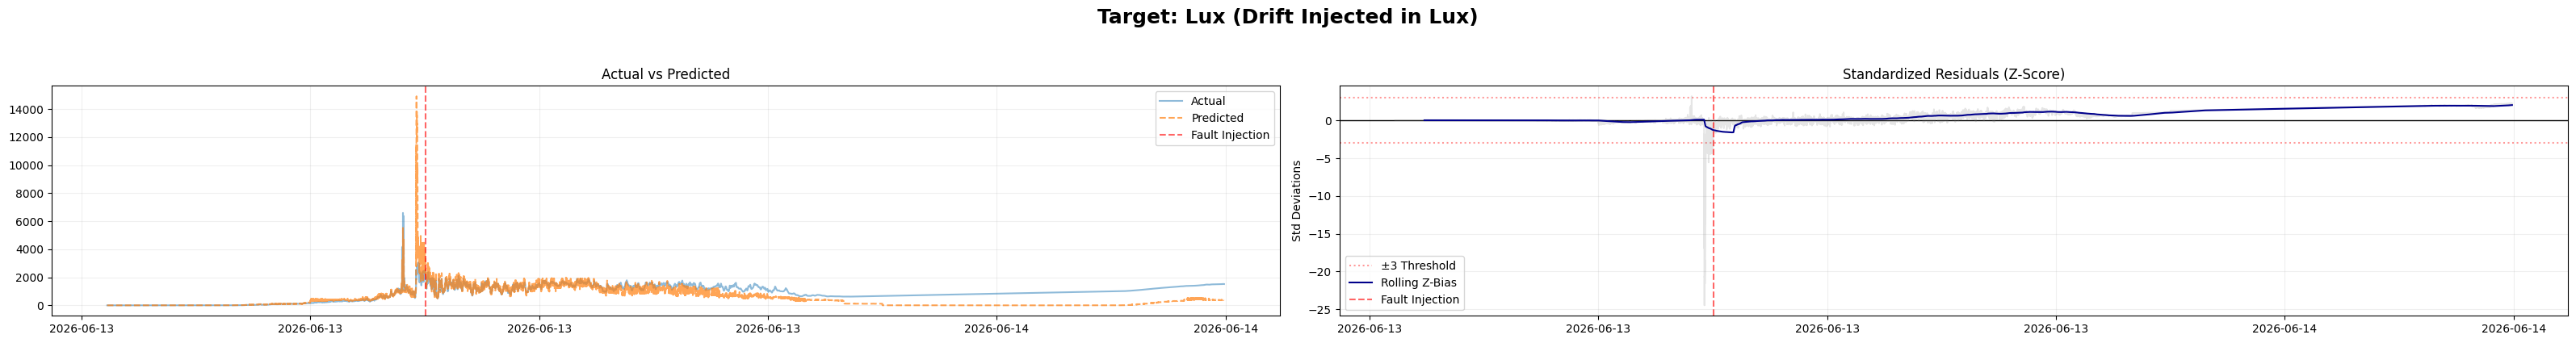

C:\Users\kisho\AppData\Local\Temp\ipykernel_29820\2818213874.py:34: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.metrics_df = pd.concat([self.metrics_df, pd.DataFrame([row])], ignore_index=True)


Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_Lux.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.25, 'limit_sigma': 2.5}, 'rolling': {'window': 10, 'threshold': 3.0}}
Weights: {'zscore': 0, 'cusum': 1, 'ewma': 2, 'rolling': 1} | Decision Threshold: 3
Tuning  - TPR: 0.588 | FPR: 0.078 | Delay: 840
Evaluation - TPR: 0.548 | FPR: 0.008 | Delay: 0

TRAINING TARGET: UVA


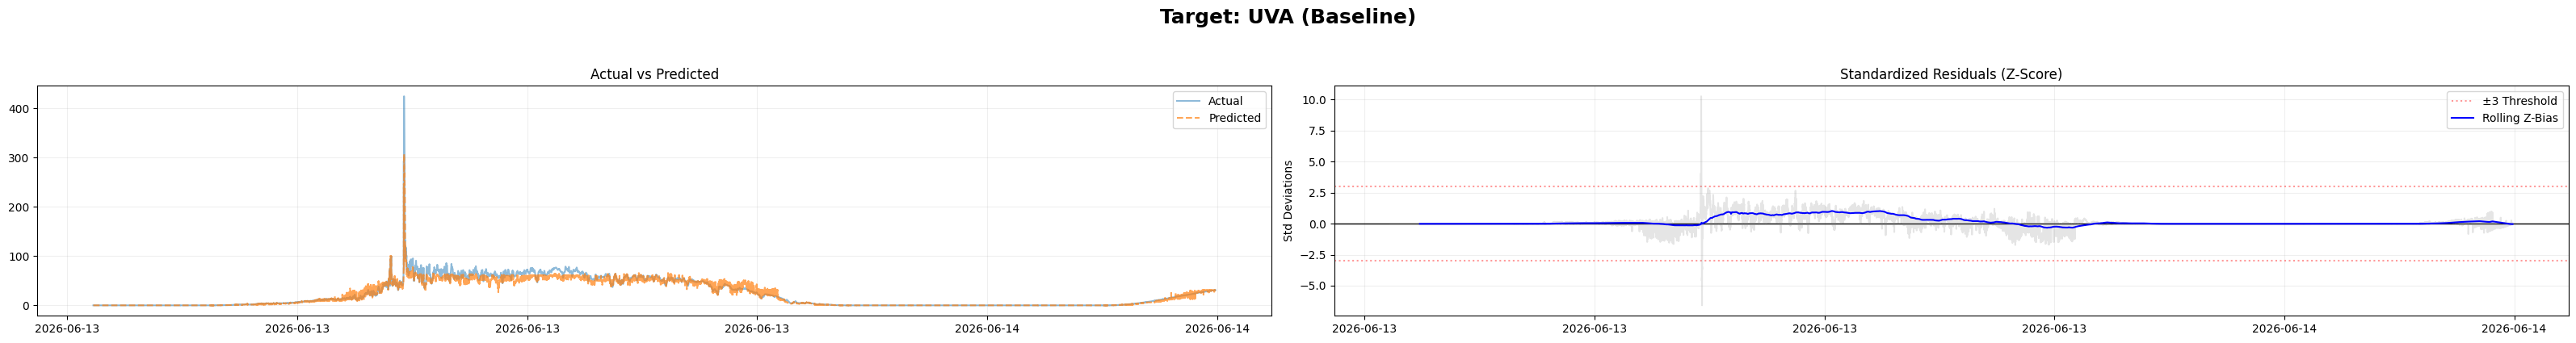

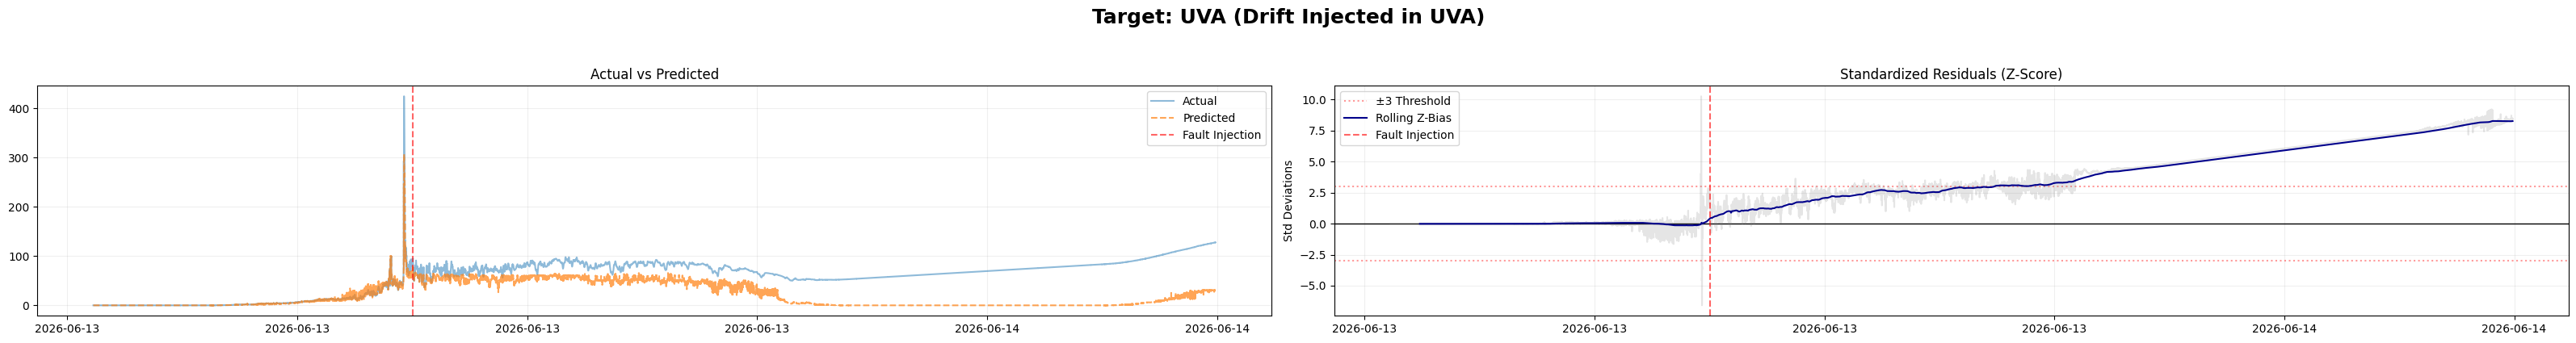

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_UVA.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 1.0, 'h': 6.0}, 'ewma': {'alpha': 0.3, 'limit_sigma': 3.0}, 'rolling': {'window': 10, 'threshold': 4.0}}
Weights: {'zscore': 0, 'cusum': 0, 'ewma': 1, 'rolling': 1} | Decision Threshold: 2
Tuning  - TPR: 0.854 | FPR: 0.009 | Delay: 448
Evaluation - TPR: 0.932 | FPR: 0.010 | Delay: 0

TRAINING TARGET: UVB


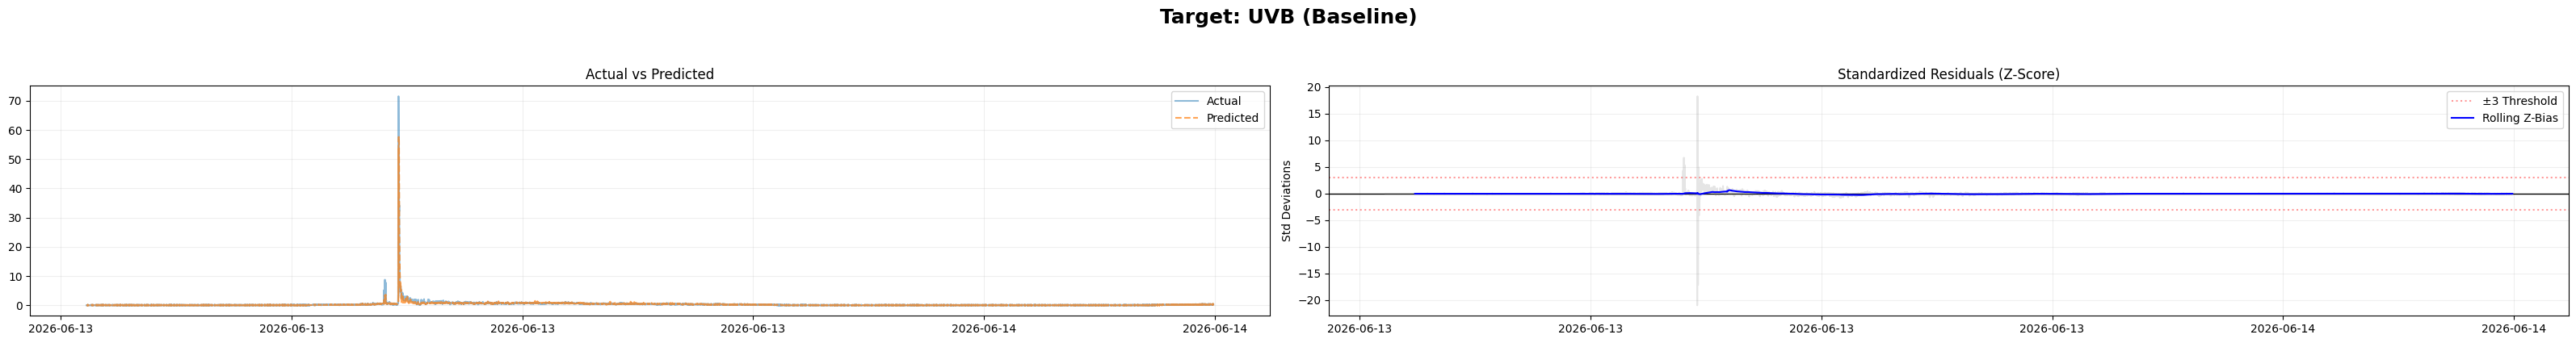

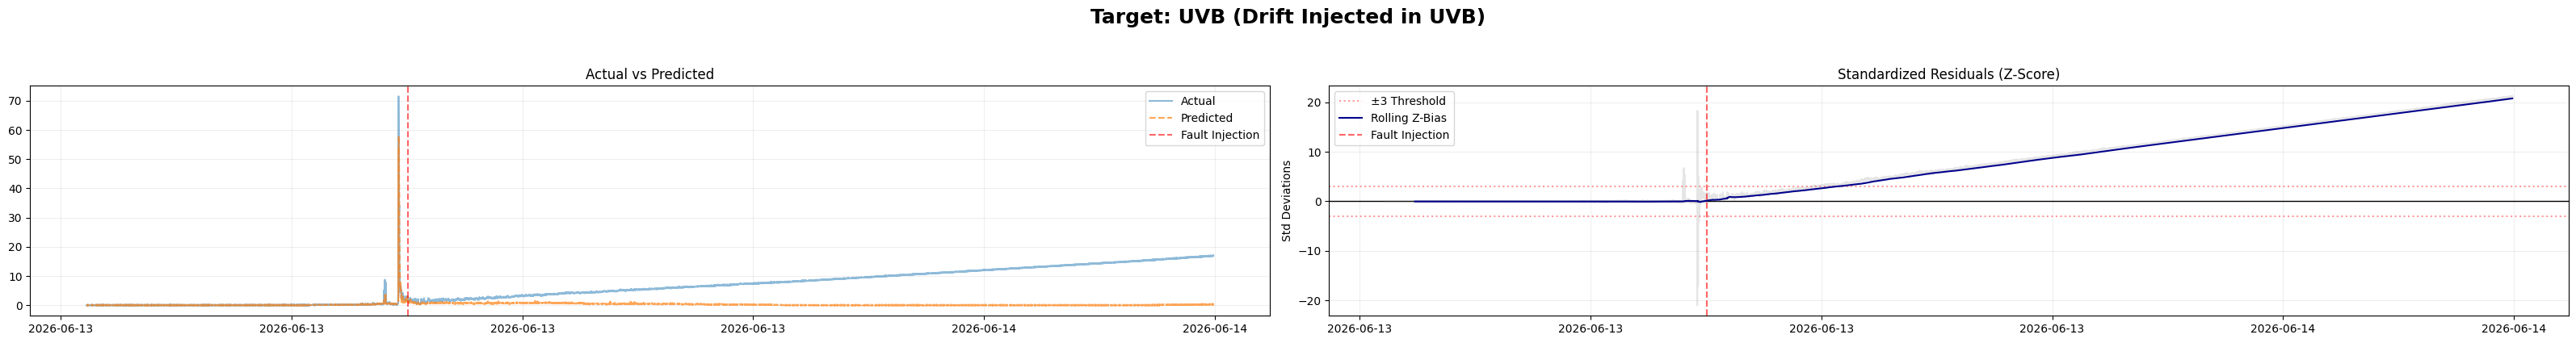

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_UVB.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.15, 'limit_sigma': 2.0}, 'rolling': {'window': 30, 'threshold': 2.0}}
Weights: {'zscore': 0, 'cusum': 0, 'ewma': 0, 'rolling': 2} | Decision Threshold: 2
Tuning  - TPR: 0.980 | FPR: 0.009 | Delay: 260
Evaluation - TPR: 0.998 | FPR: 0.033 | Delay: 0

TRAINING TARGET: UVC


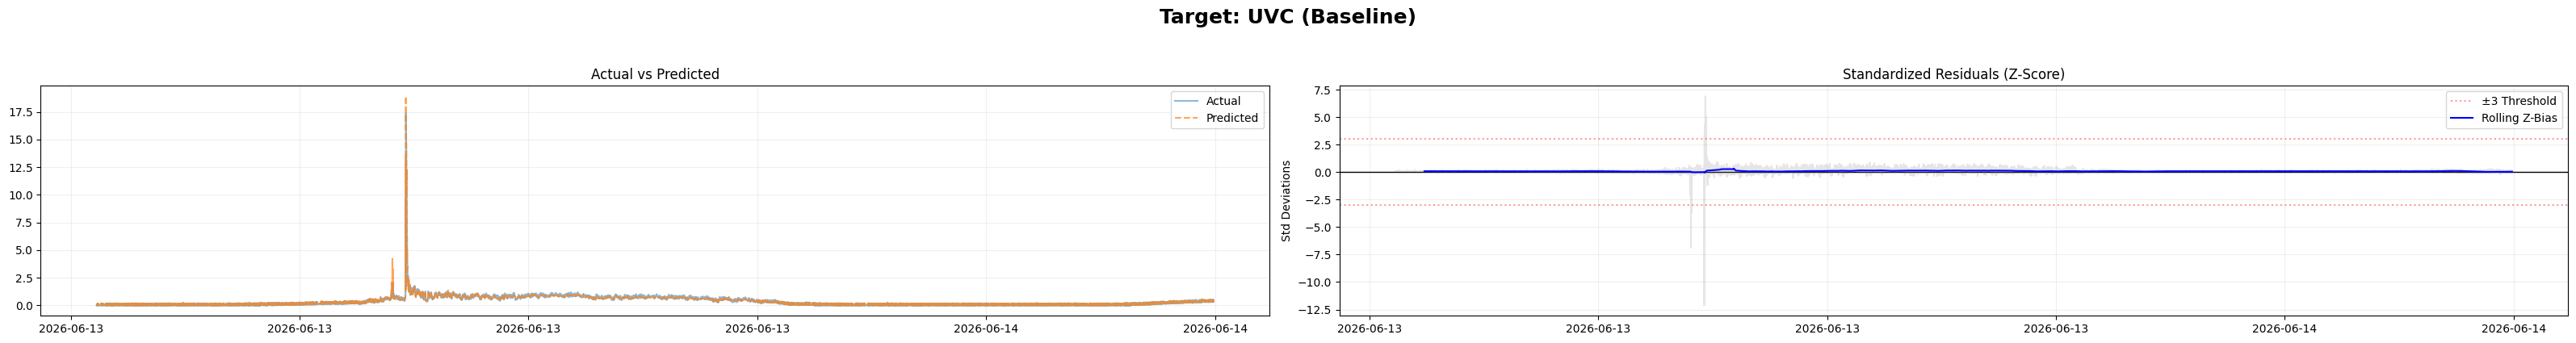

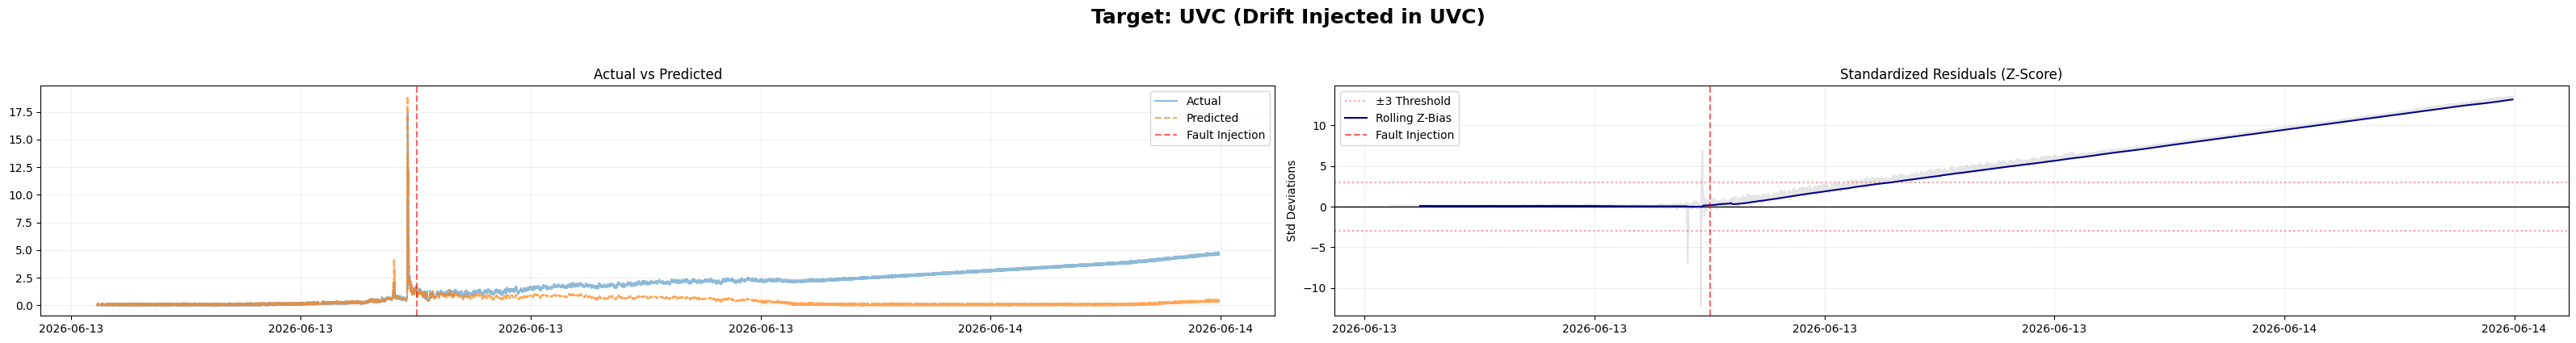

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_UVC.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 0.75, 'h': 5.0}, 'ewma': {'alpha': 0.15, 'limit_sigma': 2.0}, 'rolling': {'window': 20, 'threshold': 2.5}}
Weights: {'zscore': 1, 'cusum': 0, 'ewma': 1, 'rolling': 2} | Decision Threshold: 2
Tuning  - TPR: 0.967 | FPR: 0.007 | Delay: 412
Evaluation - TPR: 0.962 | FPR: 0.003 | Delay: 390

TRAINING TARGET: PM1.0_AVG_PPM


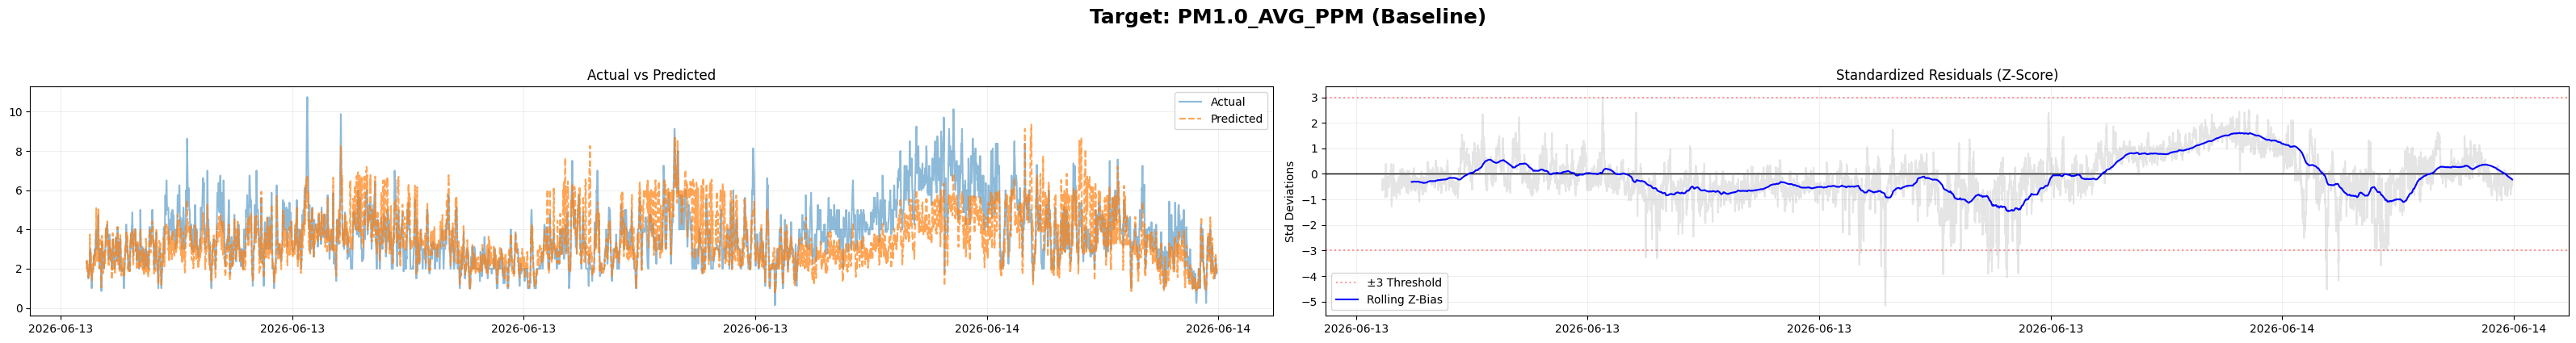

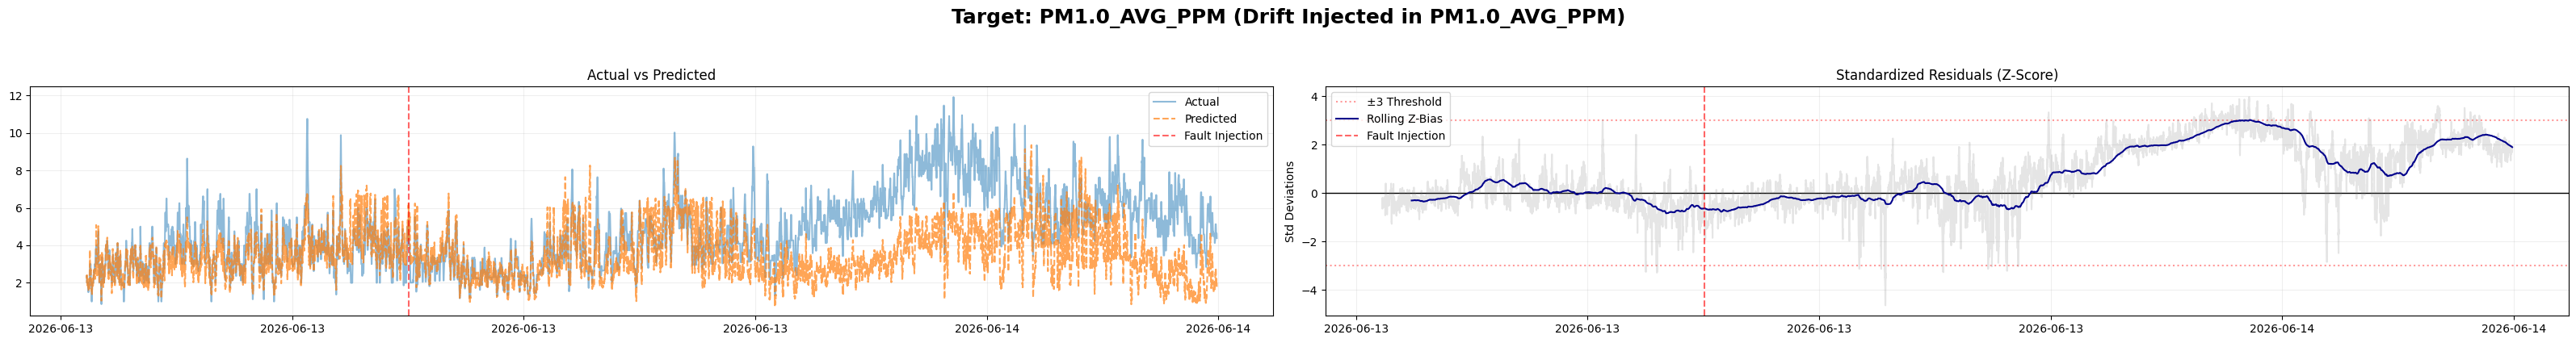

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_PM1.0_AVG_PPM.joblib
Test parameters: {'zscore': {'threshold': 4.0}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.15, 'limit_sigma': 3.5}, 'rolling': {'window': 10, 'threshold': 3.5}}
Weights: {'zscore': 0, 'cusum': 0, 'ewma': 2, 'rolling': 0} | Decision Threshold: 2
Tuning  - TPR: 0.640 | FPR: 0.127 | Delay: 483
Evaluation - TPR: 0.511 | FPR: 0.192 | Delay: 16

TRAINING TARGET: T_SCD40_C


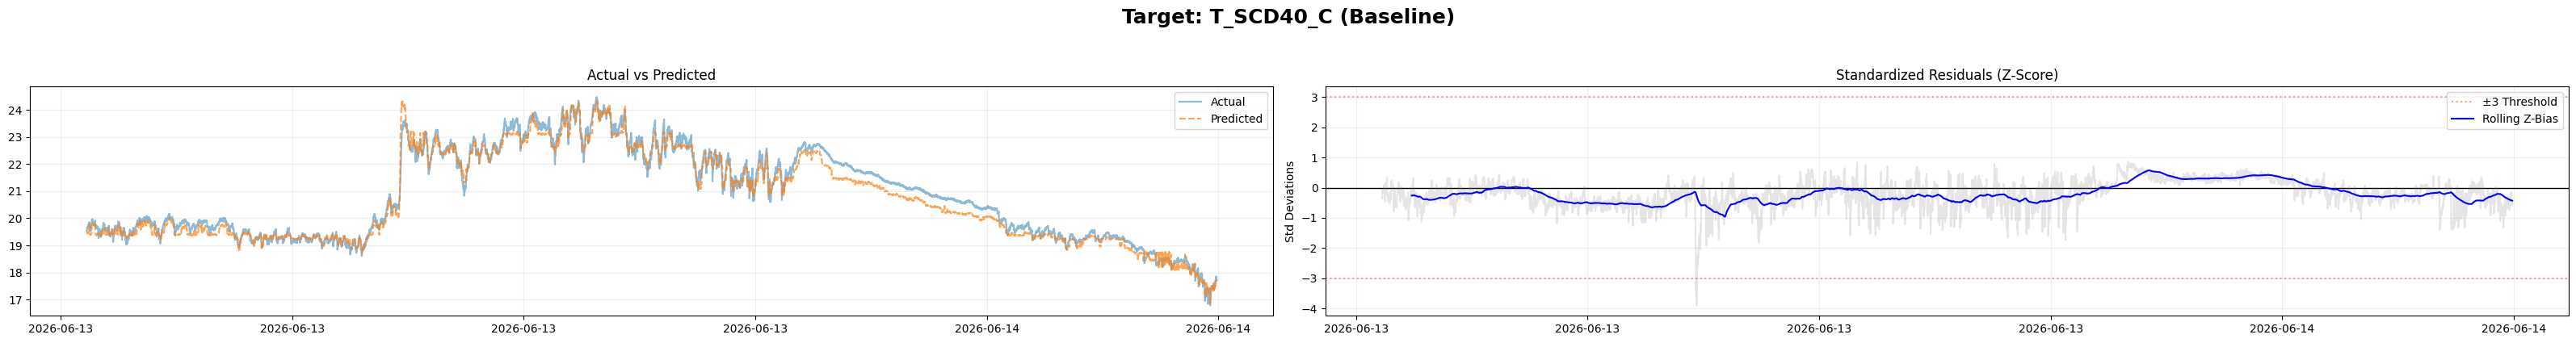

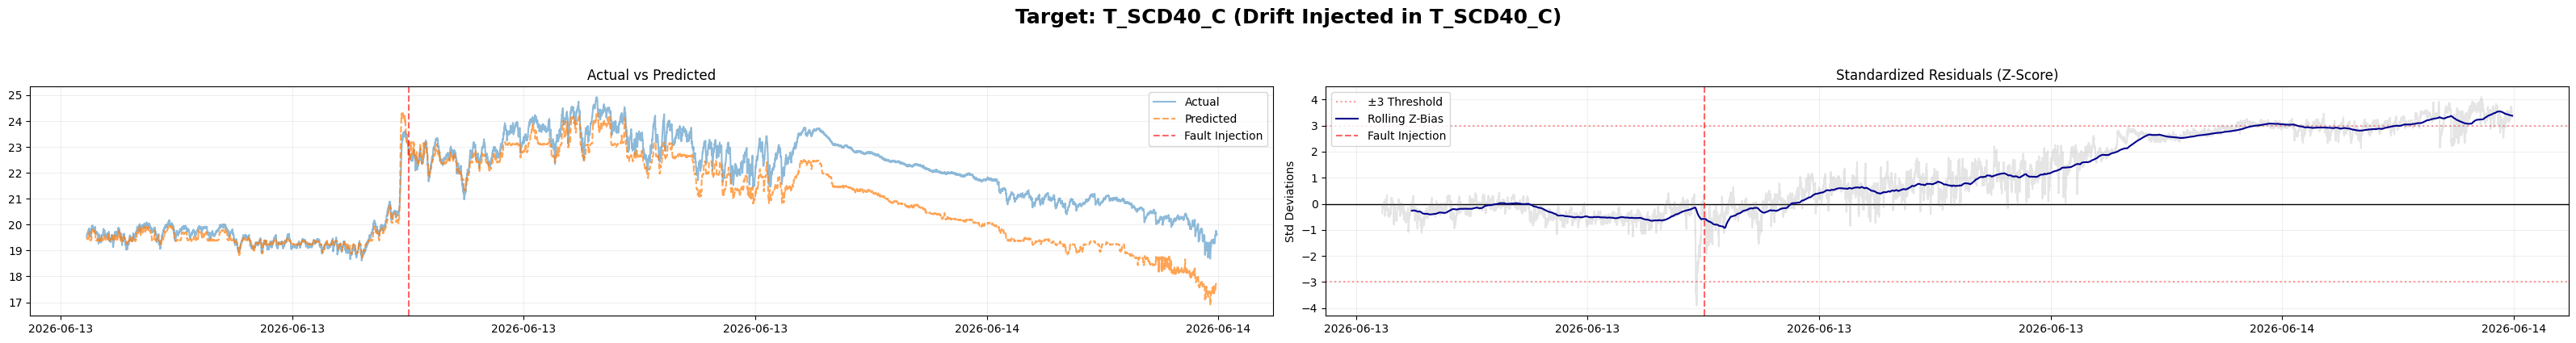

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_T_SCD40_C.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.3, 'limit_sigma': 3.5}, 'rolling': {'window': 10, 'threshold': 4.0}}
Weights: {'zscore': 1, 'cusum': 1, 'ewma': 0, 'rolling': 1} | Decision Threshold: 3
Tuning  - TPR: 0.550 | FPR: 0.068 | Delay: 3358
Evaluation - TPR: 0.496 | FPR: 0.002 | Delay: 6100

TRAINING TARGET: BME68X_TEMP_C


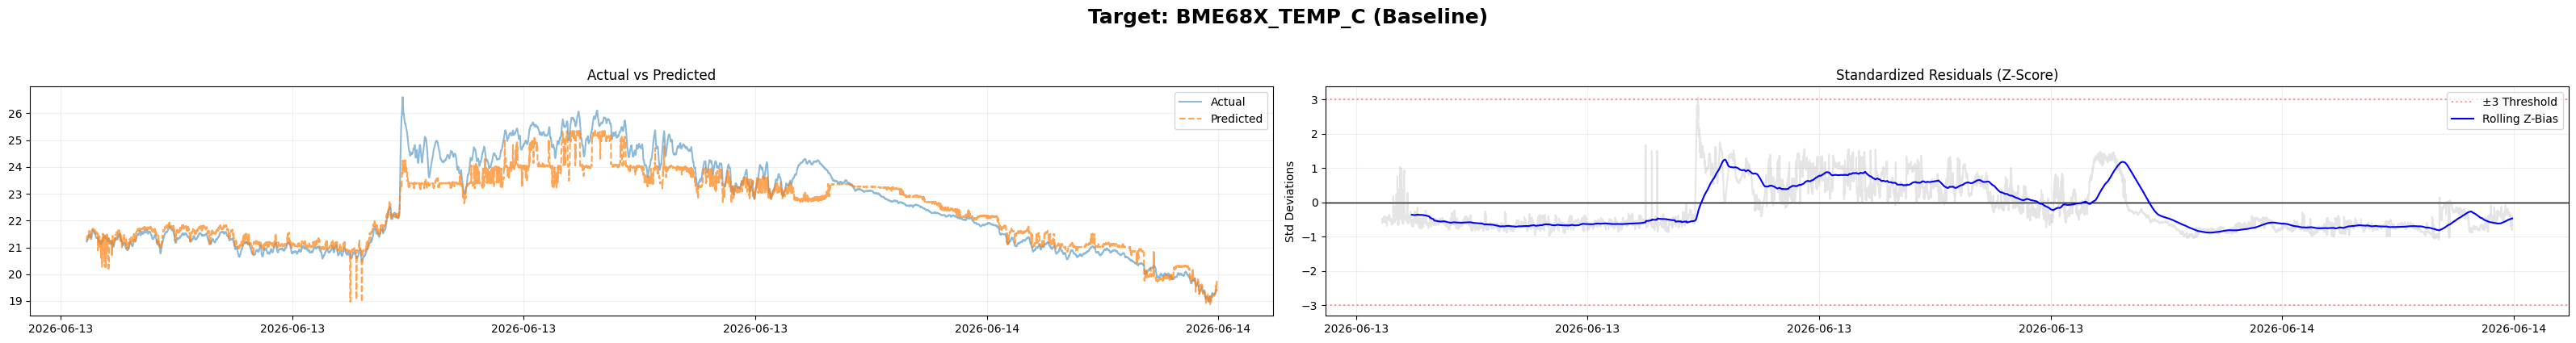

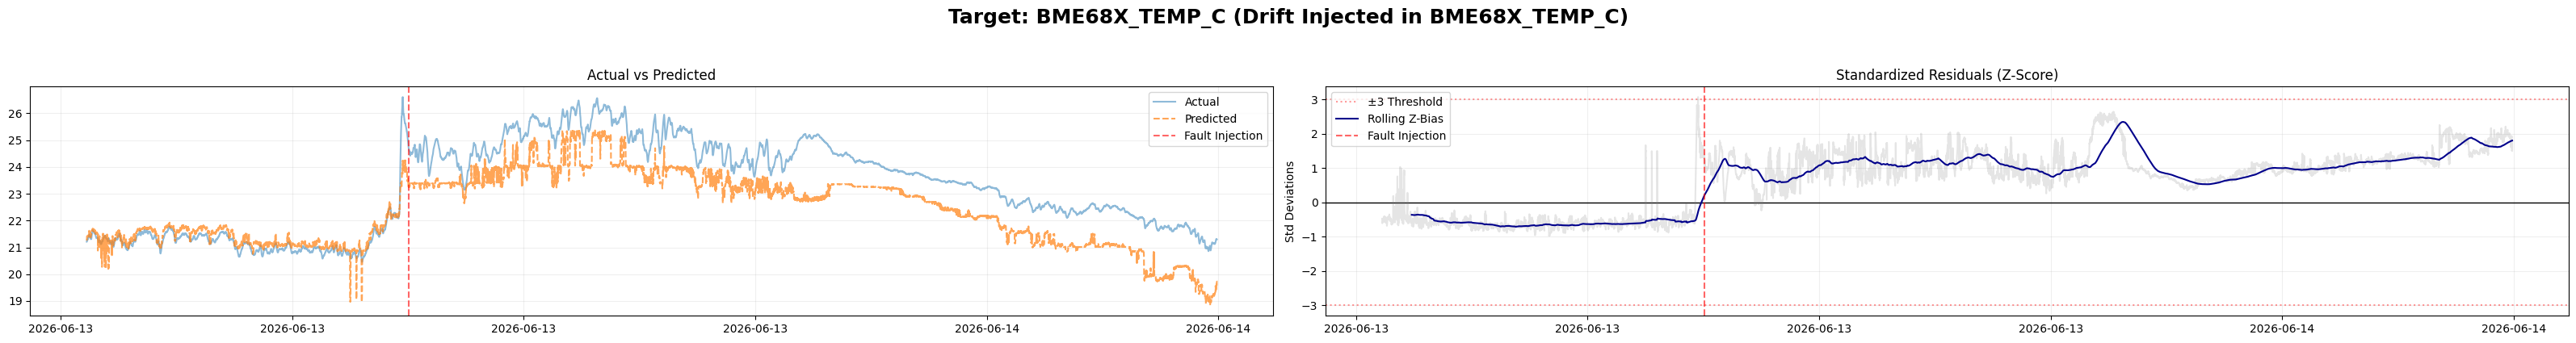

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_BME68X_TEMP_C.joblib
Test parameters: {'zscore': {'threshold': 2.5}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.25, 'limit_sigma': 3.5}, 'rolling': {'window': 10, 'threshold': 4.0}}
Weights: {'zscore': 2, 'cusum': 1, 'ewma': 1, 'rolling': 0} | Decision Threshold: 2
Tuning  - TPR: 0.464 | FPR: 0.158 | Delay: 937
Evaluation - TPR: 0.262 | FPR: 0.019 | Delay: 0

TRAINING TARGET: H_SCD40_RH


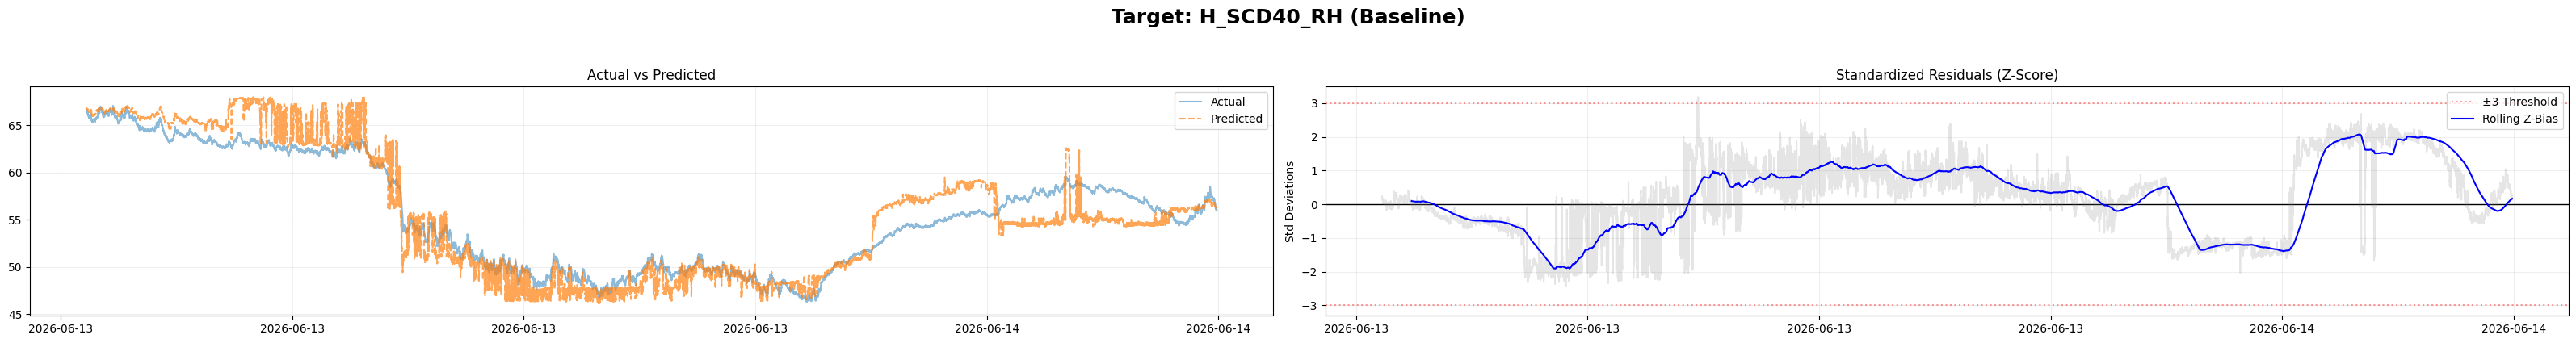

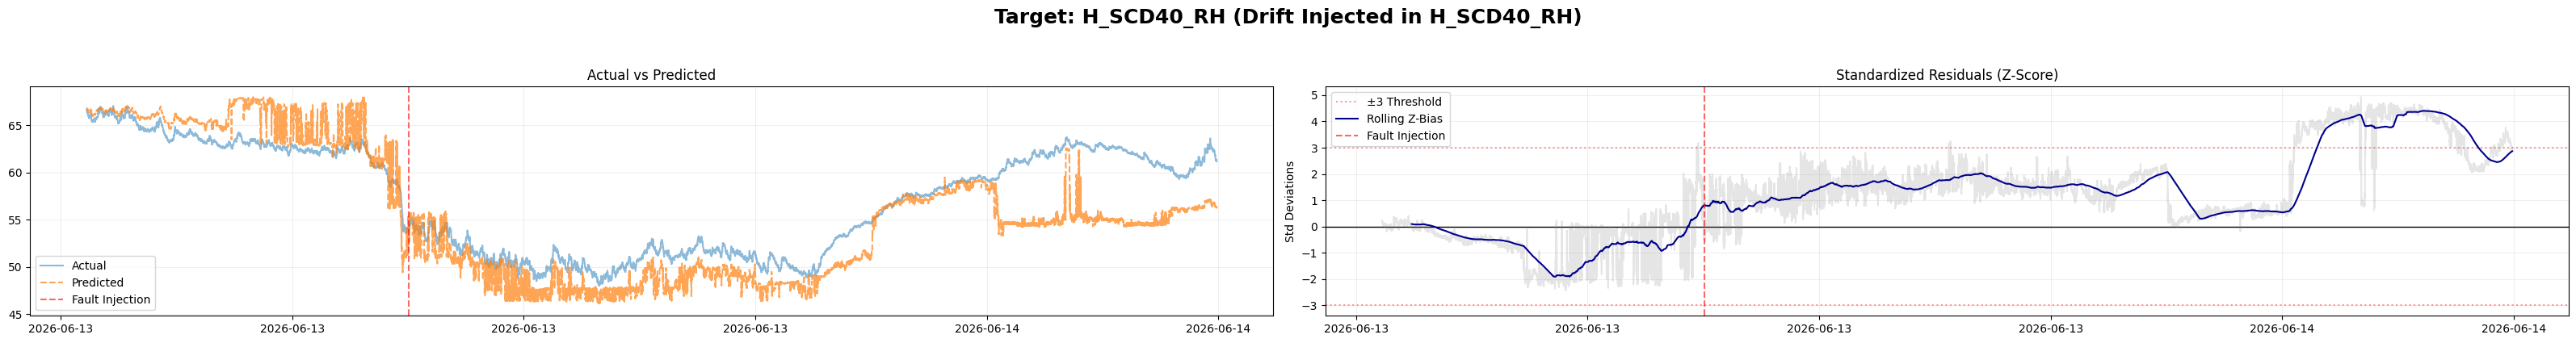

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_H_SCD40_RH.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.3, 'limit_sigma': 3.5}, 'rolling': {'window': 10, 'threshold': 4.0}}
Weights: {'zscore': 1, 'cusum': 2, 'ewma': 2, 'rolling': 1} | Decision Threshold: 5
Tuning  - TPR: 0.361 | FPR: 0.116 | Delay: 651
Evaluation - TPR: 0.514 | FPR: 0.193 | Delay: 1631

TRAINING TARGET: BME68X_HUM_RH


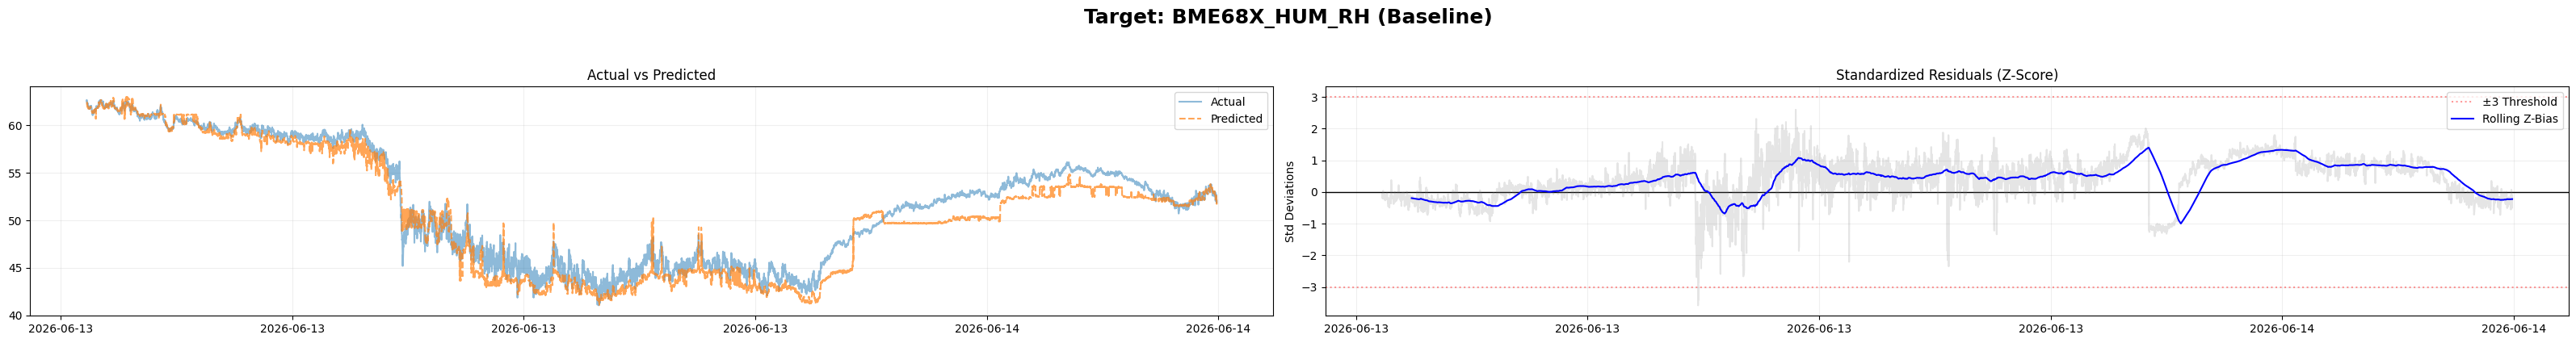

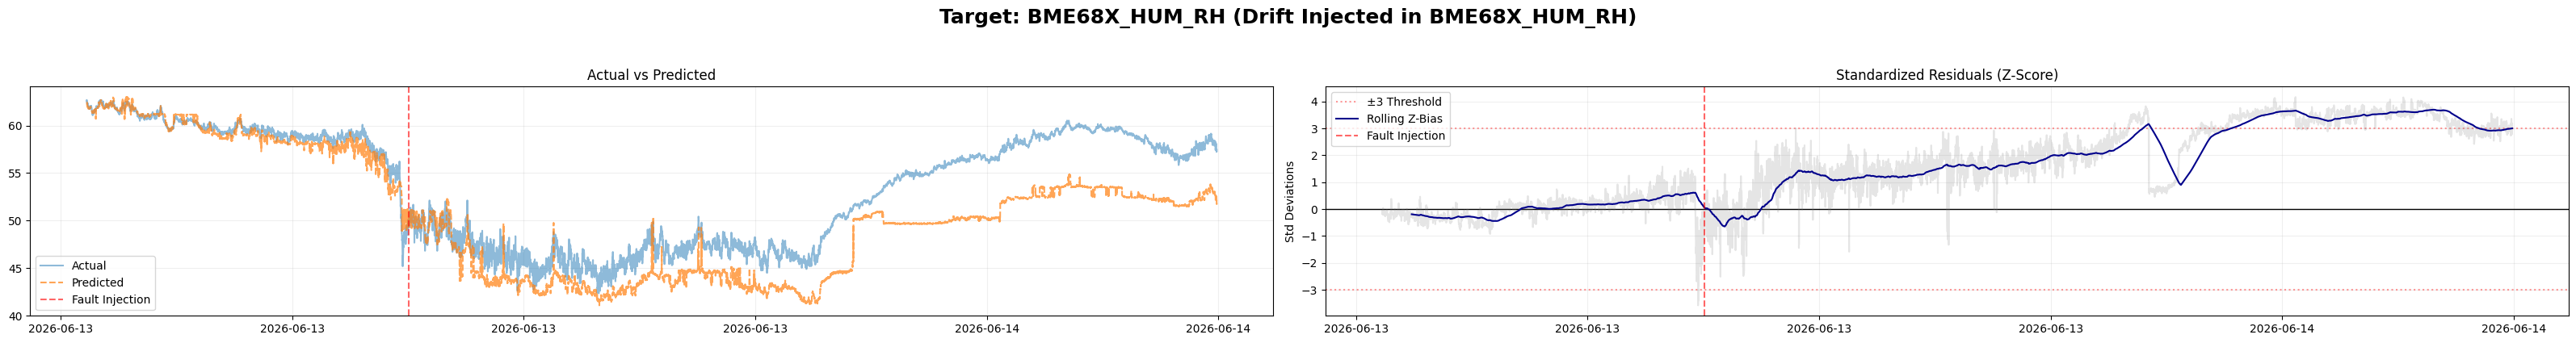

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_BME68X_HUM_RH.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.25, 'limit_sigma': 3.5}, 'rolling': {'window': 10, 'threshold': 4.0}}
Weights: {'zscore': 1, 'cusum': 2, 'ewma': 1, 'rolling': 1} | Decision Threshold: 4
Tuning  - TPR: 0.657 | FPR: 0.098 | Delay: 638
Evaluation - TPR: 0.706 | FPR: 0.034 | Delay: 662

TRAINING TARGET: BME68X_PRES_hPa


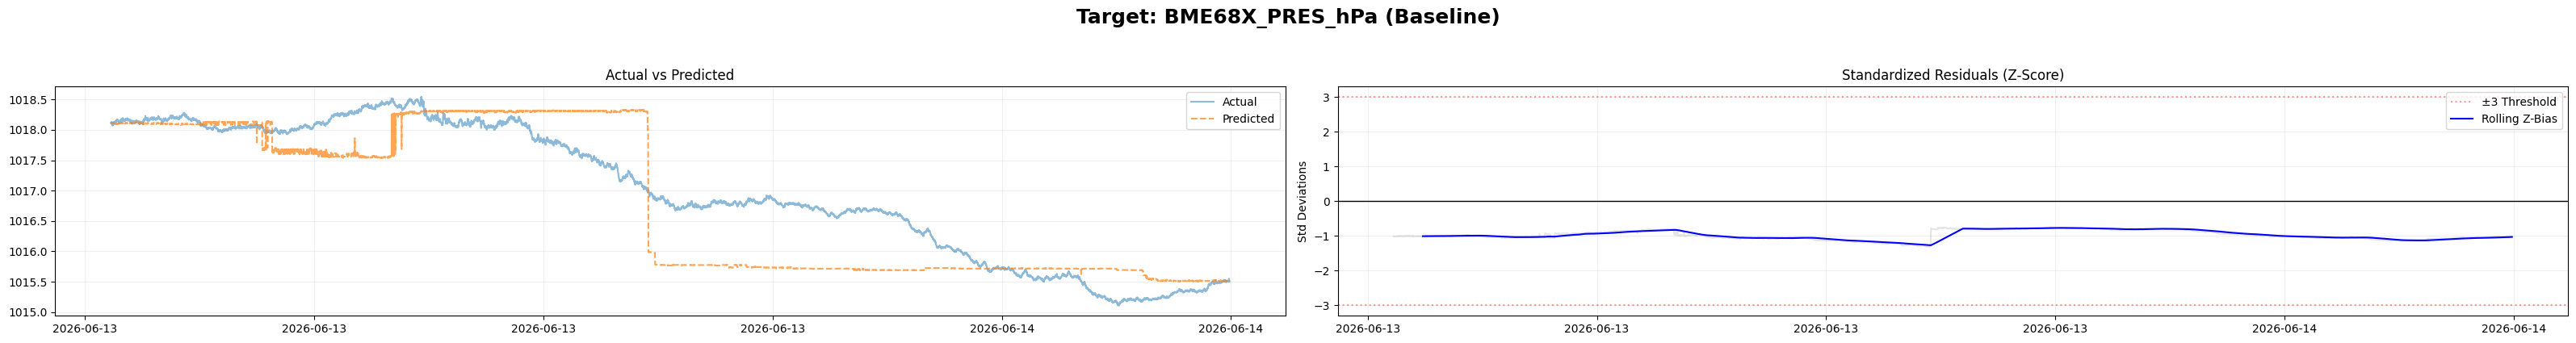

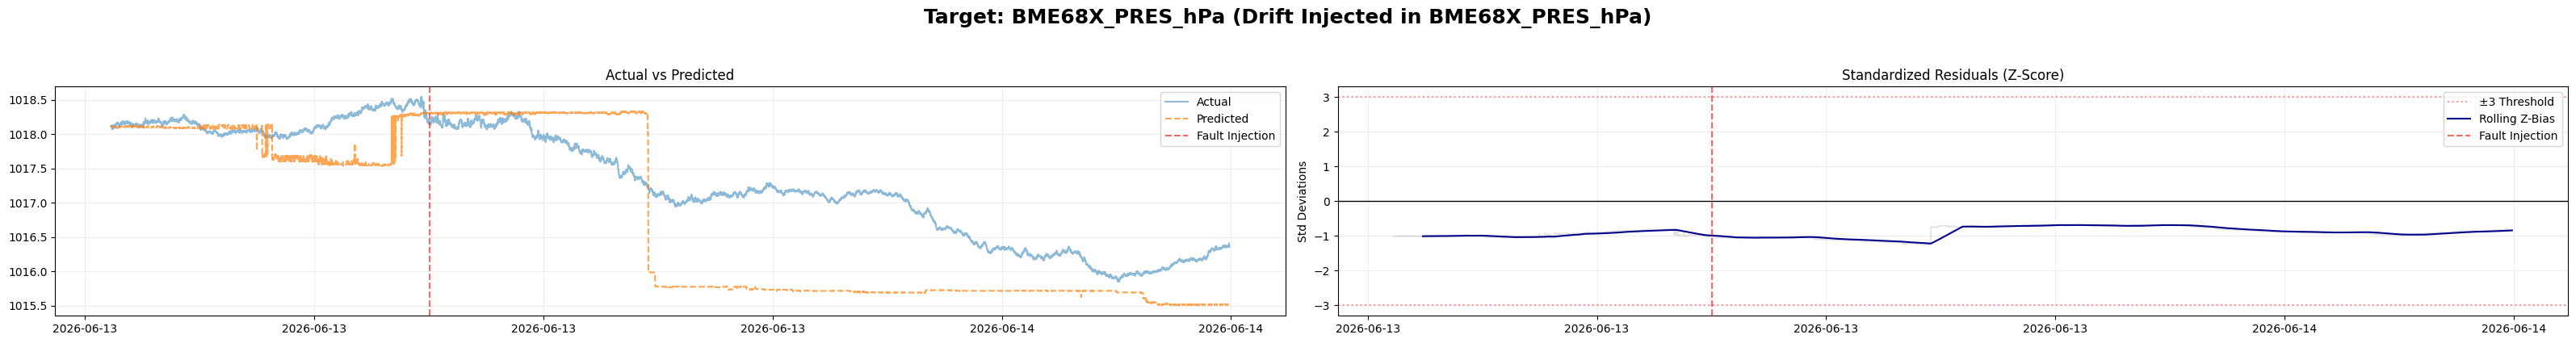

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_BME68X_PRES_hPa.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 1.0, 'h': 4.0}, 'ewma': {'alpha': 0.3, 'limit_sigma': 3.0}, 'rolling': {'window': 10, 'threshold': 4.0}}
Weights: {'zscore': 0, 'cusum': 1, 'ewma': 1, 'rolling': 0} | Decision Threshold: 2
Tuning  - TPR: 0.214 | FPR: 0.094 | Delay: 544
Evaluation - TPR: 0.000 | FPR: 0.019 | Delay: nan

TRAINING TARGET: BME68X_VOC_kOhm


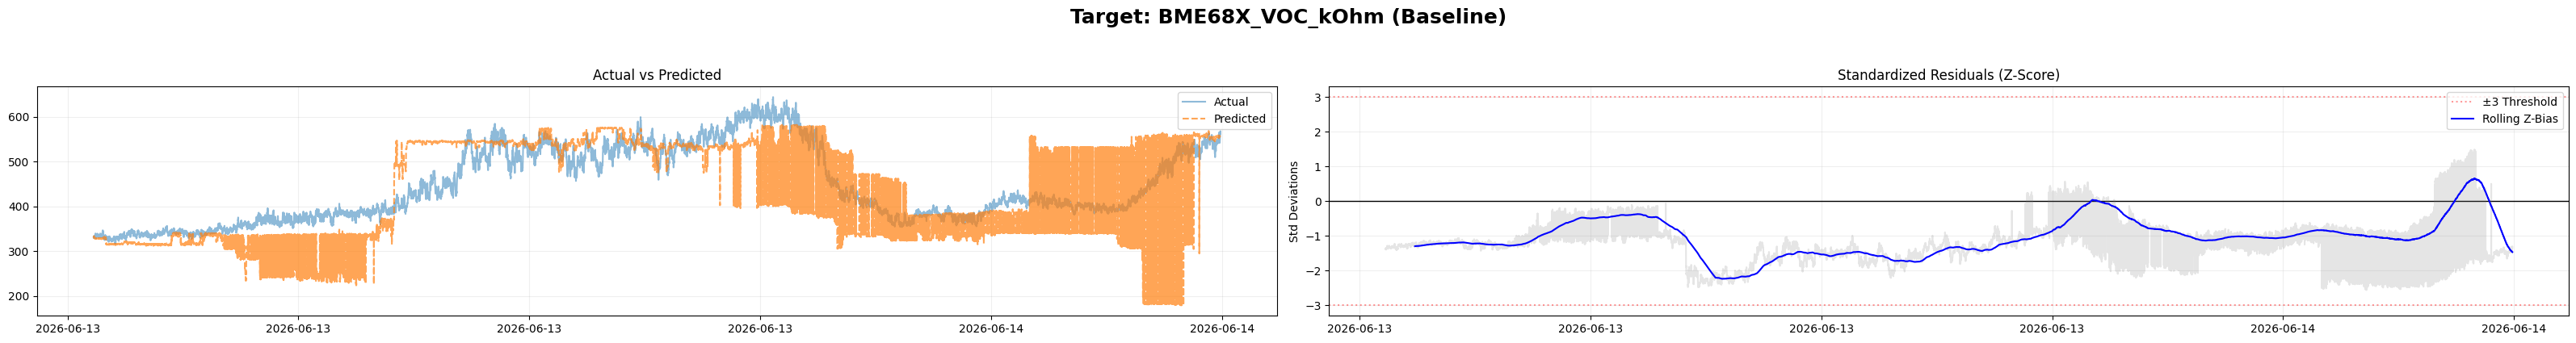

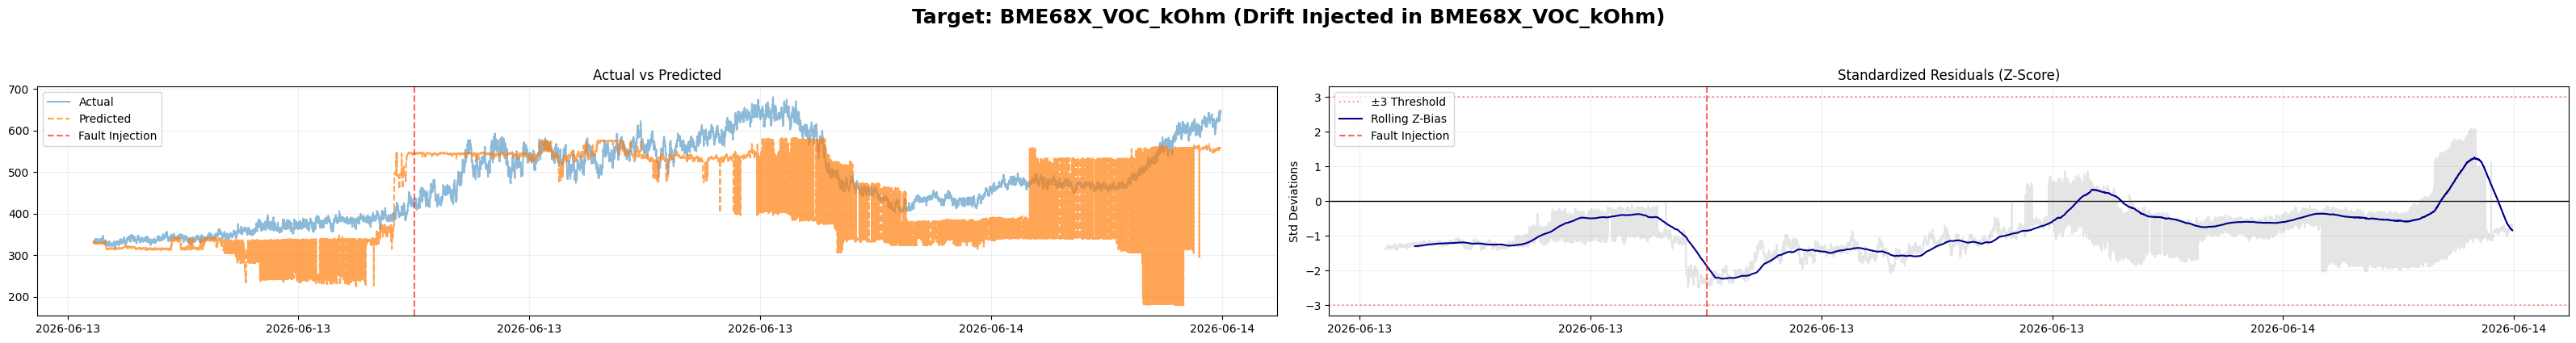

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_BME68X_VOC_kOhm.joblib
Test parameters: {'zscore': {'threshold': 2.5}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.3, 'limit_sigma': 3.5}, 'rolling': {'window': 10, 'threshold': 3.5}}
Weights: {'zscore': 1, 'cusum': 0, 'ewma': 0, 'rolling': 1} | Decision Threshold: 2
Tuning  - TPR: 0.023 | FPR: 0.006 | Delay: 3676
Evaluation - TPR: 0.000 | FPR: 0.000 | Delay: nan

TRAINING TARGET: CO_value_mV


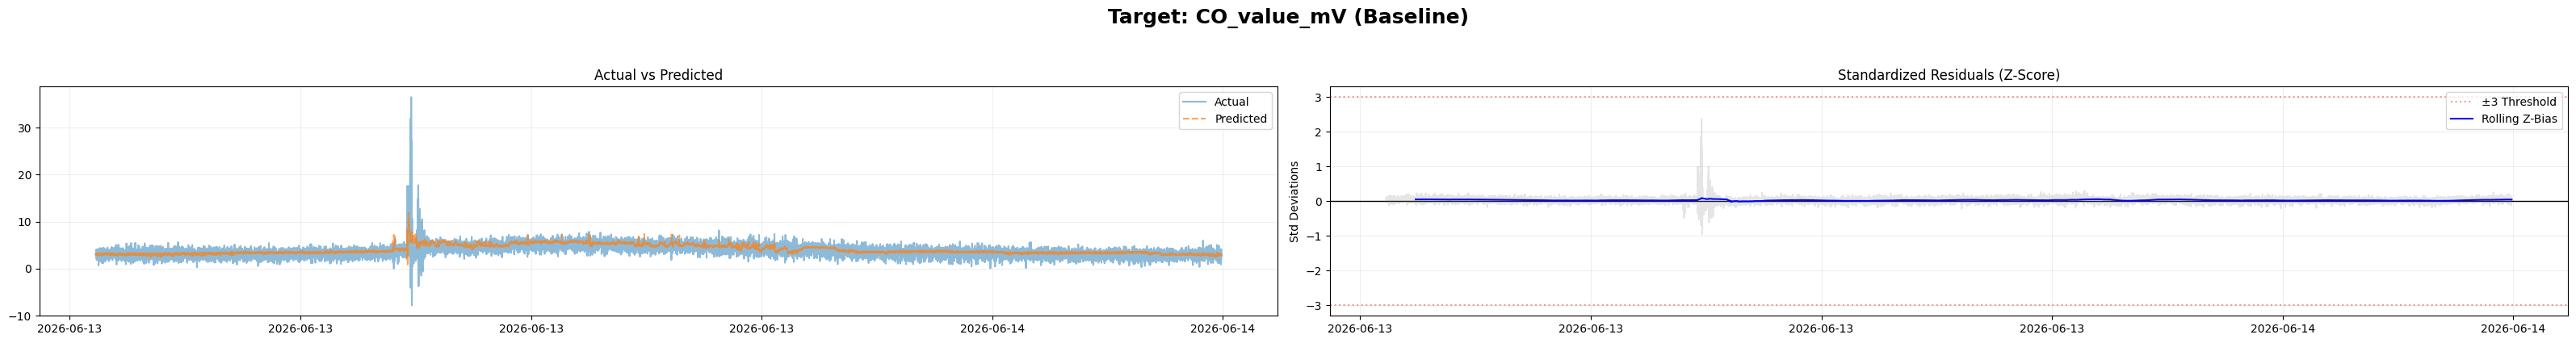

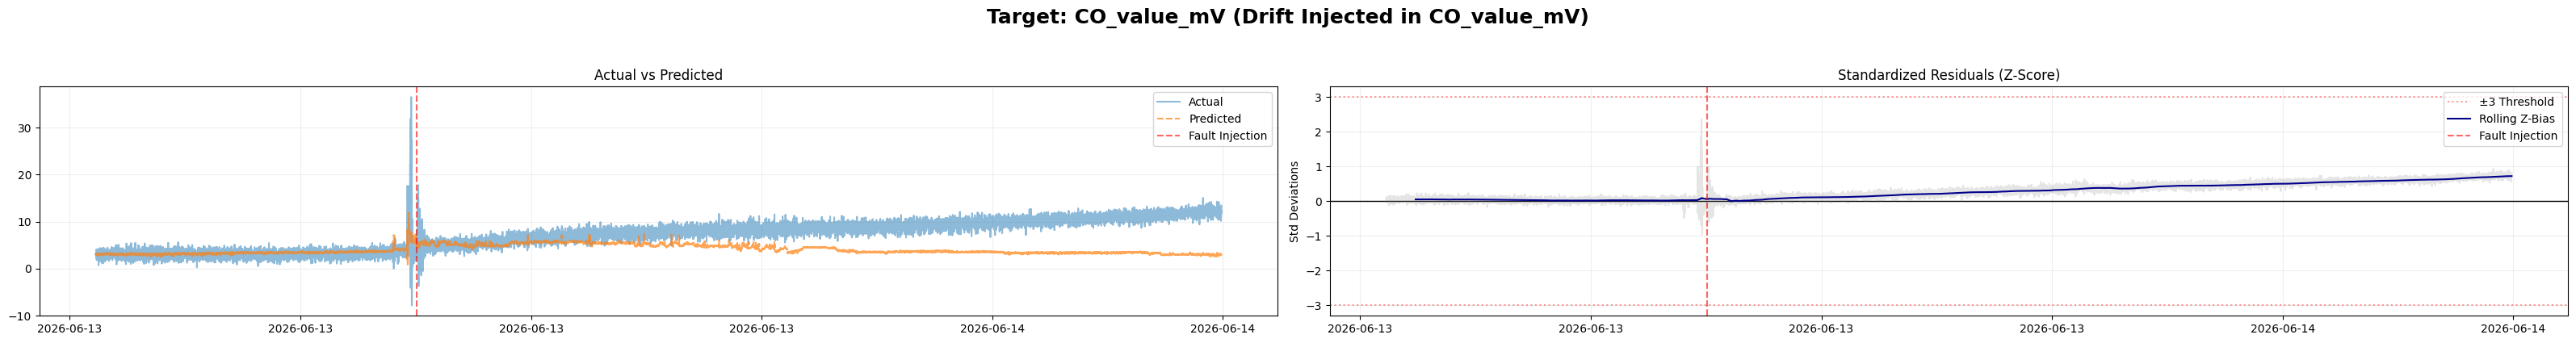

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_CO_value_mV.joblib
Test parameters: {'zscore': {'threshold': 2.5}, 'cusum': {'k': 0.25, 'h': 8.0}, 'ewma': {'alpha': 0.1, 'limit_sigma': 2.0}, 'rolling': {'window': 100, 'threshold': 2.0}}
Weights: {'zscore': 0, 'cusum': 1, 'ewma': 1, 'rolling': 1} | Decision Threshold: 2
Tuning  - TPR: 0.829 | FPR: 0.021 | Delay: 2173
Evaluation - TPR: 0.645 | FPR: 0.002 | Delay: 4508

TRAINING TARGET: CO2_ppm


C:\Users\kisho\AppData\Local\Temp\ipykernel_29820\1873235658.py:36: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[564.         564.00390182 564.00780365 ... 567.52194635 582.52584818
 548.52975   ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  corrupted.iloc[start_index:] = series.iloc[start_index:] + drift_steps
C:\Users\kisho\AppData\Local\Temp\ipykernel_29820\1873235658.py:36: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[431.         431.00390152 431.00780303 ... 491.52194697 490.52584848
 490.52975   ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  corrupted.iloc[start_index:] = series.iloc[start_index:] + drift_steps


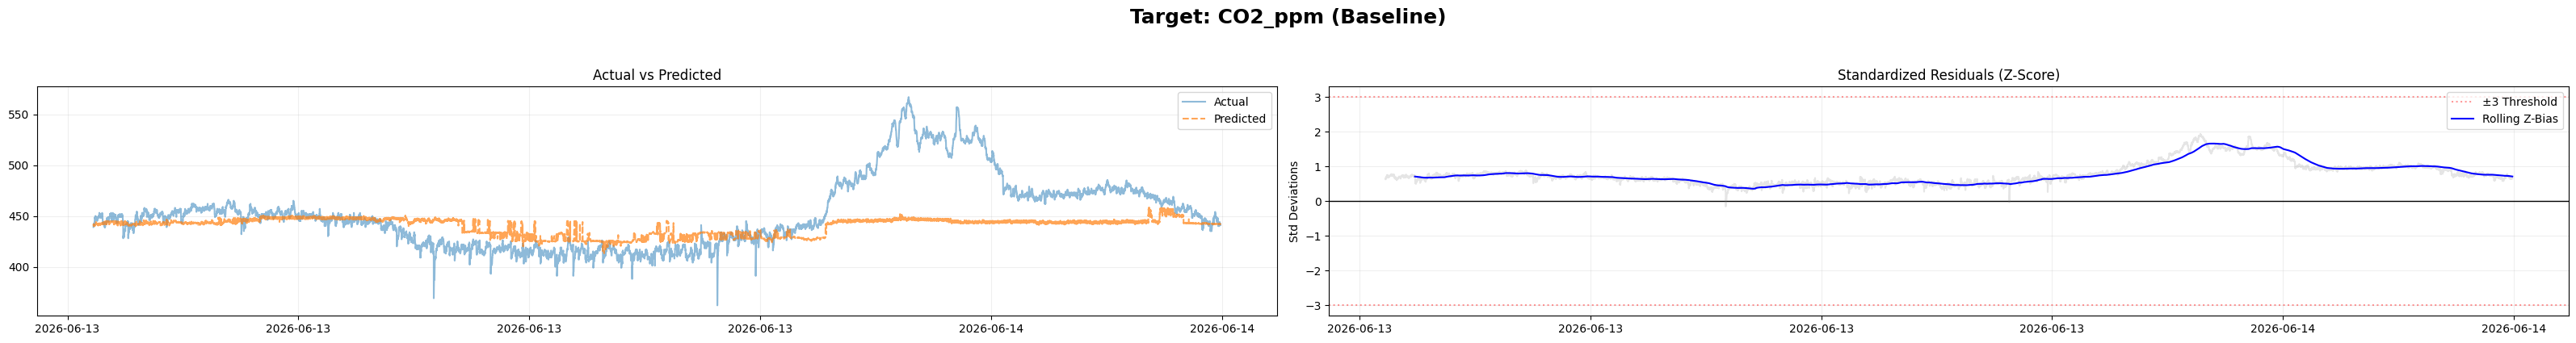

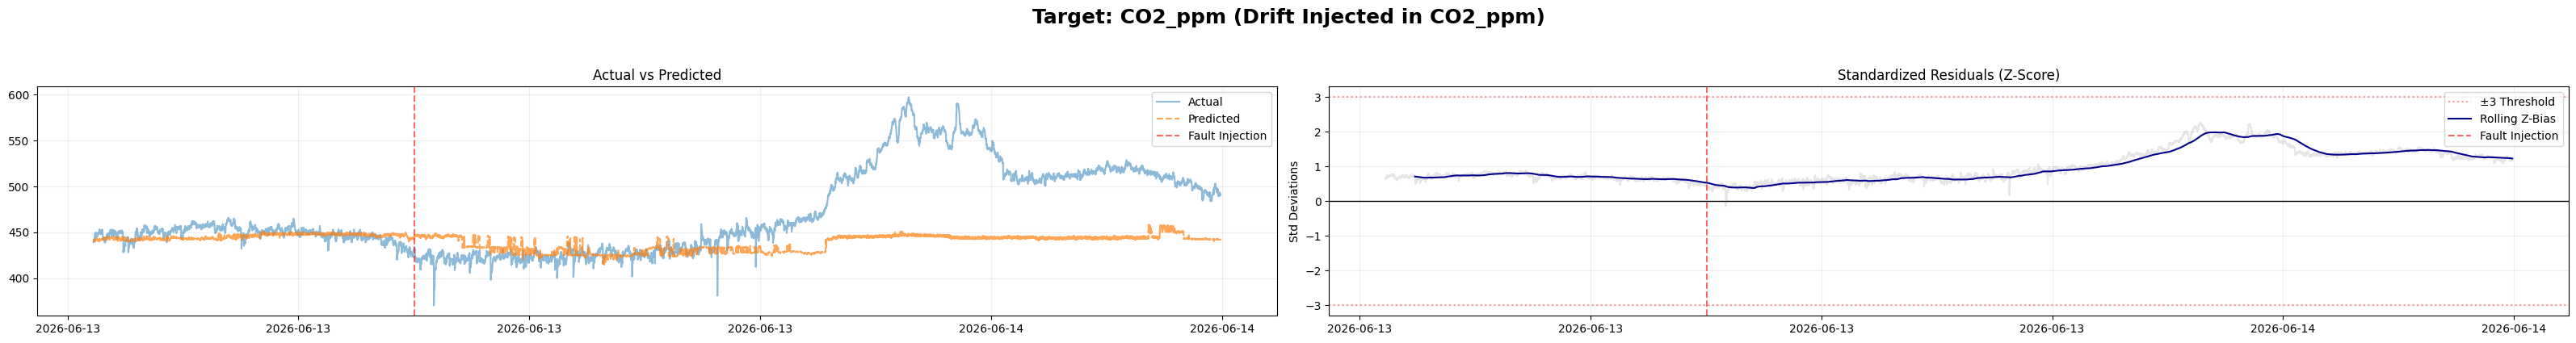

Saved: ../saved_models_noref_temp/Halle_1/detector_RandomForest_CO2_ppm.joblib
Test parameters: {'zscore': {'threshold': 2.0}, 'cusum': {'k': 1.0, 'h': 8.0}, 'ewma': {'alpha': 0.3, 'limit_sigma': 3.5}, 'rolling': {'window': 10, 'threshold': 4.0}}
Weights: {'zscore': 1, 'cusum': 0, 'ewma': 0, 'rolling': 1} | Decision Threshold: 2
Tuning  - TPR: 0.015 | FPR: 0.000 | Delay: 7994
Evaluation - TPR: 0.023 | FPR: 0.000 | Delay: 7705

Stored 13 evaluation results in memory.


In [8]:
# TRAINING: BUILD ONE MINIMAL DEPLOYABLE DETECTOR PER SENSOR
import os
import joblib
import numpy as np
from sklearn.base import clone

weight_options = [0, 1, 2]
decision_threshold_options = [2, 3, 4, 5, 6, 7, 8]
persistence_min_run = 15
fpr_penalty = 2.0
max_fpr = 0.30

for target, drift_total in drift_amounts.items():
    if skip_training:
        print("Skipping Training")
        break
    if target not in df_numeric_clean.columns:
        print(f"Skipping {target}: column is not present in df_numeric_clean.")
        continue

    print(f"\n{'=' * 60}\nTRAINING TARGET: {target}\n{'=' * 60}")
    X_train, y_train, X_tune, y_tune, t_tune, tune_start_index, tune_fault_time, X_eval, y_eval, t_eval, eval_start_index, eval_fault_time = prepare_target_data(target)

    # 1. Train the regression model on the first 60%
    model = clone(base_models[selected_model])
    model.fit(X_train, y_train)

    # 2. Use the next 20% to define the healthy residual baseline and tune the detector to maximize TPR and minimize FPR
    y_pred_tune_healthy = model.predict(X_tune)
    raw_res_tune_healthy = y_tune.to_numpy() - y_pred_tune_healthy
    mu, sigma = float(np.mean(raw_res_tune_healthy)), float(np.std(raw_res_tune_healthy) + 1e-8)
    z_tune_healthy = (raw_res_tune_healthy - mu) / sigma

    y_tune_faulty = induce_drift(y_tune, drift_total, tune_start_index)
    y_pred_tune_faulty = model.predict(X_tune)
    raw_res_tune_faulty = y_tune_faulty.to_numpy() - y_pred_tune_faulty
    z_tune_faulty = (raw_res_tune_faulty - mu) / sigma

    best = optimize_detector_rule(z_tune_healthy, z_tune_faulty, tune_start_index, test_param_grid=TEST_PARAM_GRID, weight_options=weight_options, decision_threshold_options=decision_threshold_options, min_run=persistence_min_run, fpr_penalty=fpr_penalty, max_fpr=max_fpr)

    # 3. Freeze the detector and evaluate it on the untouched final 20%
    y_pred_eval_healthy = model.predict(X_eval)
    raw_res_eval_healthy = y_eval.to_numpy() - y_pred_eval_healthy
    z_eval_healthy = (raw_res_eval_healthy - mu) / sigma
    tests_eval_healthy = run_statistical_tests(z_eval_healthy, best["test_params"])
    flags_eval_healthy = apply_weights(tests_eval_healthy, best["weights"], threshold=best["decision_threshold"], min_run=persistence_min_run)

    y_eval_faulty = induce_drift(y_eval, drift_total, eval_start_index)
    y_pred_eval_faulty = model.predict(X_eval)
    raw_res_eval_faulty = y_eval_faulty.to_numpy() - y_pred_eval_faulty
    z_eval_faulty = (raw_res_eval_faulty - mu) / sigma
    tests_eval_faulty = run_statistical_tests(z_eval_faulty, best["test_params"])
    flags_eval_faulty = apply_weights(tests_eval_faulty, best["weights"], threshold=best["decision_threshold"], min_run=persistence_min_run)
    evaluation_metrics = evaluate_flags(flags_eval_healthy, flags_eval_faulty, eval_start_index, fpr_penalty=fpr_penalty, max_fpr=max_fpr)["metrics"]

    plot_diagnostic_grid(target, selected_model, t_eval, y_eval, y_pred_eval_healthy, raw_res_eval_healthy, z_eval_healthy)
    plot_diagnostic_grid(target, selected_model, t_eval, y_eval_faulty, y_pred_eval_faulty, raw_res_eval_faulty, z_eval_faulty, fault_sensor=target, fault_time=eval_fault_time)

    # 4. Save detector
    detector = {
        "target": target,
        "model": model,
        "feature_columns": X_train.columns.tolist(),
        "normalization": {"mu": mu, "sigma": sigma},
        "rule": {"test_params": best["test_params"], "weights": best["weights"], "decision_threshold": best["decision_threshold"], "persistence_min_run": persistence_min_run},
    }
    detector_filename = os.path.join(model_dir_temp, f"detector_{selected_model}_{target}.joblib")
    joblib.dump(detector, detector_filename)

    # 5. Store results in memory for visualizations
    drift_results_manager.add_result(device, target, target, selected_model, evaluation_metrics, test_placement, model_train_fraction, detector_tune_fraction, evaluation_fraction)

    print(f"Saved: {detector_filename}")
    print(f"Test parameters: {best['test_params']}")
    print(f"Weights: {best['weights']} | Decision Threshold: {best['decision_threshold']}")
    print(f"Tuning  - TPR: {best['metrics']['TPR_faulty']:.3f} | FPR: {best['metrics']['FPR_healthy']:.3f} | Delay: {best['metrics']['delay']}")
    print(f"Evaluation - TPR: {evaluation_metrics['TPR_faulty']:.3f} | FPR: {evaluation_metrics['FPR_healthy']:.3f} | Delay: {evaluation_metrics['delay']}")

if not skip_training:
    print(f"\nStored {len(drift_results_manager.metrics_df)} evaluation results in memory.")


In [9]:
# EVALUATION AND VISUALIZATION FUNCTIONS
import os
import joblib
import numpy as np

def evaluate_detector(target, fault_sensor=None, drift_amount=None, verbose=False, store_result=True):
    """Evaluate one saved detector"""
    # if target not in drift_amounts:
    #     raise KeyError(f"No trained drift configuration is defined for target {target!r}.")

    fault_sensor = target if fault_sensor is None else fault_sensor
    if fault_sensor not in drift_amounts and drift_amount is None:
        raise KeyError(f"No drift amount is configured for fault sensor {fault_sensor!r}.")

    # detector_filename = os.path.join(model_dir, f"detector_{selected_model}_{target}.joblib")
    detector_filename = os.path.join(model_dir_temp, f"detector_{selected_model}_{target}.joblib")
    if not os.path.exists(detector_filename):
        raise FileNotFoundError(f"Missing trained detector for {target}: {detector_filename}. Run the training block first.")

    detector = joblib.load(detector_filename)
    model, feature_columns = detector["model"], detector["feature_columns"]
    mu, sigma = detector["normalization"]["mu"], detector["normalization"]["sigma"]
    test_params, weights = detector["rule"]["test_params"], detector["rule"]["weights"]
    threshold = detector["rule"]["decision_threshold"]
    min_run = detector["rule"]["persistence_min_run"]

    split = drift_results_manager.get_split_config(device, target, selected_model)
    saved_placement = split.get("test_placement", test_placement)
    saved_train_fraction = split.get("model_train_fraction", model_train_fraction)
    saved_tune_fraction = split.get("detector_tune_fraction", detector_tune_fraction)
    saved_eval_fraction = split.get("evaluation_fraction", evaluation_fraction)

    _, _, _, _, _, _, _, X_eval, y_eval, t_eval, start_index, fault_time = prepare_target_data(target, placement=saved_placement, model_train_fraction_value=saved_train_fraction, detector_tune_fraction_value=saved_tune_fraction, evaluation_fraction_value=saved_eval_fraction)

    missing_features = [column for column in feature_columns if column not in X_eval.columns]
    if missing_features:
        raise KeyError(f"Target {target!r} is missing trained feature columns: {missing_features}")
    X_eval = X_eval.loc[:, feature_columns]

    y_pred_healthy = model.predict(X_eval)
    raw_res_healthy = y_eval.to_numpy() - y_pred_healthy
    z_healthy = (raw_res_healthy - mu) / sigma
    tests_healthy = run_statistical_tests(z_healthy, test_params)
    flags_healthy = apply_weights(tests_healthy, weights, threshold=threshold, min_run=min_run)

    X_faulty, y_faulty = X_eval.copy(), y_eval.copy()
    drift_total = drift_amounts[fault_sensor] if drift_amount is None else drift_amount
    if fault_sensor == target:
        y_faulty = induce_drift(y_faulty, drift_total, start_index)
    else:
        if fault_sensor not in X_faulty.columns:
            raise KeyError(f"Fault sensor {fault_sensor!r} is not an input feature for target {target!r}.")
        X_faulty[fault_sensor] = induce_drift(X_faulty[fault_sensor], drift_total, start_index)

    y_pred_faulty = model.predict(X_faulty)
    raw_res_faulty = y_faulty.to_numpy() - y_pred_faulty
    z_faulty = (raw_res_faulty - mu) / sigma
    tests_faulty = run_statistical_tests(z_faulty, test_params)
    flags_faulty = apply_weights(tests_faulty, weights, threshold=threshold, min_run=min_run)

    _, healthy_fpr = calculate_rates(flags_healthy, start_index, is_healthy=True)
    faulty_tpr, faulty_fpr = calculate_rates(flags_faulty, start_index, is_healthy=False)
    metrics = {"TPR_faulty": faulty_tpr, "FPR_faulty": faulty_fpr, "FPR_healthy": healthy_fpr, "delay": detection_delay(flags_faulty, start_index)}

    result = {
        "device": device,
        "target": target,
        "fault_sensor": fault_sensor,
        "timestamps": t_eval.to_numpy(),
        "fault_time": fault_time,
        "start_index": start_index,
        "y_healthy": y_eval.to_numpy(),
        "y_faulty": y_faulty.to_numpy(),
        "y_pred_healthy": y_pred_healthy,
        "y_pred_faulty": y_pred_faulty,
        "raw_residual_healthy": raw_res_healthy,
        "raw_residual_faulty": raw_res_faulty,
        "z_healthy": z_healthy,
        "z_faulty": z_faulty,
        "test_flags_healthy": tests_healthy,
        "test_flags_faulty": tests_faulty,
        "flags_healthy": flags_healthy,
        "flags_faulty": flags_faulty,
        "metrics": metrics,
        "drift_amount": drift_total,
    }

    if store_result:
        drift_results_manager.add_result(device, target, fault_sensor, selected_model, metrics, saved_placement, saved_train_fraction, saved_tune_fraction, saved_eval_fraction)

    if verbose:
        print(f"Device: {device} | Target: {target} | Fault: {fault_sensor}")
        print(f"Test parameters: {test_params}")
        print(f"Weights: {weights} | Decision Threshold: {threshold} | Min Run: {min_run}")
        print(f"TPR: {faulty_tpr:.3f} | FPR: {healthy_fpr:.3f} | Delay: {metrics['delay']}")

    return result


def plot_systemwide_results(fault_sensor=None, drift_amount=None):
    """Plot TPR and healthy FPR for every target detector."""

    targets = list(drift_amount.keys()) if isinstance(drift_amount, dict) else [target for target in drift_amounts if target in df_numeric_clean.columns]
    targets = [target for target in targets if target in df_numeric_clean.columns]

    results = {}

    for target in targets:
        fault = target if fault_sensor is None else fault_sensor
        amount = drift_amount[fault] if isinstance(drift_amount, dict) else drift_amounts[fault] if drift_amount is None else drift_amount

        results[target] = evaluate_detector(target, fault, drift_amount=amount)

        print(f"{target:20s} drift={amount:8.3f}  TPR={results[target]['metrics']['TPR_faulty']:.3f}  FPR={results[target]['metrics']['FPR_healthy']:.3f}")

    tpr = [results[target]["metrics"]["TPR_faulty"] for target in targets]
    fpr = [results[target]["metrics"]["FPR_healthy"] for target in targets]
    x = np.arange(len(targets))
    width = 0.35

    plt.figure(figsize=(14, 6))
    plt.grid(True, axis="y", linestyle="--", alpha=0.8, zorder=0)
    plt.bar(x - width / 2, tpr, width, label="TPR", color="blue", alpha=0.8, zorder=3)
    plt.bar(x + width / 2, fpr, width, label="FPR", color="red", alpha=0.8, zorder=3)
    plt.title("Fault Detection Performance")
    plt.xticks(x, targets, rotation=45, ha="right")
    plt.ylim(0, 1.05)
    plt.axhline(0.3, color="red", linestyle="--", alpha=0.5, label="FPR Threshold (0.3)")
    plt.ylabel("Rate")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return results


def plot_systemwide_aggregate_results(fault_sensor=None, error_metric="sem", devices=None):
    """
    Plot mean TPR/FPR across current in-memory device evaluations with device-level error bars.

    Keep the same drift_results_manager instance while switching devices. Training
    adds self-fault results, and plot_systemwide_results(<sensor>) adds cross-fault
    results. fault_sensor=None aggregates each target's self-fault result.
    """
    if error_metric not in {"std", "sem"}:
        raise ValueError("error_metric must be either 'std' or 'sem'.")

    metrics_df = drift_results_manager.metrics_df.copy()

    if devices is not None:
        metrics_df = metrics_df[metrics_df["Device"].isin(list(devices))]

    if fault_sensor is None:
        metrics_df = metrics_df[metrics_df["Fault_Sensor"] == metrics_df["Target"]]
    else:
        metrics_df = metrics_df[metrics_df["Fault_Sensor"] == fault_sensor]

    if metrics_df.empty:
        requested = "self-fault" if fault_sensor is None else f"fault_sensor={fault_sensor!r}"
        raise ValueError(f"No in-memory held-out results found for {requested}.")

    target_order = ["Lux", "UVA", "UVB", "UVC", "PM1.0_AVG_PPM", "T_SCD40_C", "BME68X_TEMP_C", "H_SCD40_RH", "BME68X_HUM_RH", "CO_value_mV", "CO2_ppm", "BME68X_PRES_hPa", "BME68X_VOC_kOhm"]
    targets = [target for target in target_order if target in metrics_df["Target"].unique()]
    rows = []

    for target in targets:
        target_df = metrics_df[metrics_df["Target"] == target]
        tpr_values = target_df["TPR"].dropna().astype(float)
        fpr_values = target_df["FPR_Healthy"].dropna().astype(float)

        if error_metric == "std":
            tpr_error = tpr_values.std(ddof=1) if len(tpr_values) > 1 else 0.0
            fpr_error = fpr_values.std(ddof=1) if len(fpr_values) > 1 else 0.0
        else:
            tpr_error = tpr_values.sem() if len(tpr_values) > 1 else 0.0
            fpr_error = fpr_values.sem() if len(fpr_values) > 1 else 0.0

        rows.append({
            "Target": target,
            "TPR_Mean": tpr_values.mean(),
            "TPR_Error": tpr_error,
            "FPR_Mean": fpr_values.mean(),
            "FPR_Error": fpr_error,
            "N_Devices": target_df["Device"].nunique(),
        })

    summary_df = pd.DataFrame(rows)
    x = np.arange(len(summary_df))
    width = 0.35

    tpr_mean = summary_df["TPR_Mean"].to_numpy(dtype=float)
    fpr_mean = summary_df["FPR_Mean"].to_numpy(dtype=float)
    tpr_error = summary_df["TPR_Error"].fillna(0).to_numpy(dtype=float)
    fpr_error = summary_df["FPR_Error"].fillna(0).to_numpy(dtype=float)

    tpr_yerr = np.vstack([np.minimum(tpr_error, tpr_mean), np.minimum(tpr_error, 1.0 - tpr_mean)])
    fpr_yerr = np.vstack([np.minimum(fpr_error, fpr_mean), np.minimum(fpr_error, 1.0 - fpr_mean)])

    label_map = {
        "Lux": "Lux",
        "UVA": "UVA",
        "UVB": "UVB",
        "UVC": "UVC",
        "PM1.0_AVG_PPM": "PM1",
        "T_SCD40_C": "Temp\n(SCD40)",
        "BME68X_TEMP_C": "Temp\n(BME68X)",
        "H_SCD40_RH": "Humidity\n(SCD40)",
        "BME68X_HUM_RH": "Humidity\n(BME68X)",
        "BME68X_PRES_hPa": "Pressure",
        "BME68X_VOC_kOhm": "VOC",
        "CO_value_mV": "CO",
        "CO2_ppm": "CO$_2$",
    }

    xlabels = [label_map.get(target, target) for target in summary_df["Target"]]

    plt.figure(figsize=(16, 6))
    plt.grid(True, axis="y", linestyle="--", alpha=0.8, zorder=0)
    plt.bar(x - width / 2, tpr_mean, width, yerr=tpr_yerr, capsize=4, label="TPR", color="blue", alpha=0.8, zorder=3)
    plt.bar(x + width / 2, fpr_mean, width, yerr=fpr_yerr, capsize=4, label="FPR", color="red", alpha=0.8, zorder=3)

    plt.title("Aggregate Drift Detection Performance", fontsize=18)
    plt.xticks(x, xlabels, rotation=0, ha="center", fontsize=13)
    plt.yticks(fontsize=13)
    plt.ylim(0, 1.05)
    plt.axhline(0.3, color="red", linestyle="--", alpha=0.5, label="FPR Threshold (0.3)")
    plt.ylabel("Rate", fontsize=16)

    ax = plt.gca()
    handles, labels = ax.get_legend_handles_labels()
    
    threshold_handle = handles[labels.index("FPR Threshold (0.3)")]
    tpr_handle = handles[labels.index("TPR")]
    fpr_handle = handles[labels.index("FPR")]
    
    legend1 = ax.legend([threshold_handle], ["FPR Threshold (0.3)"], loc="upper right", bbox_to_anchor=(0.99, 0.99), frameon=False, fontsize=16)
    ax.add_artist(legend1)
    
    ax.legend([tpr_handle, fpr_handle], ["TPR", "FPR"], loc="upper right", bbox_to_anchor=(0.99, 0.93), ncol=2, frameon=False, fontsize=16)

    plt.tight_layout()
    plt.show()

    return {"details": metrics_df, "summary": summary_df}


def plot_target_timeseries(target, fault_sensor=None, drift_amount=None):
    """Plot healthy and fault-injected residuals with the final ensemble flags."""
    result = evaluate_detector(target, fault_sensor, drift_amount=drift_amount)
    timestamps = result["timestamps"]
    metrics = result["metrics"]

    fig, axes = plt.subplots(2, 1, figsize=(20, 10), sharex=True)
    fig.suptitle(f"Detection Results: Target={target}, Fault={result['fault_sensor']}", fontsize=16, fontweight="bold", y=1.0)

    # Healthy scenario
    axes[0].plot(timestamps, result["z_healthy"], alpha=0.8, color="gray", label="Z-Residual")
    axes[0].axhline(3, color="red", linestyle=":", alpha=0.4, label="±3 Threshold")
    axes[0].axhline(-3, color="red", linestyle=":", alpha=0.4)
    axes[0].set_ylabel("Z-Score (Std Deviations)", color="gray")
    axes[0].set_title(f"Healthy Baseline (FPR: {metrics['FPR_healthy']:.3f})")
    healthy_flag_axis = axes[0].twinx()
    healthy_flag_axis.step(timestamps, result["flags_healthy"], where="post", alpha=0.8, color="red", linewidth=2.5, label="Final Fault Flag")
    healthy_flag_axis.set_ylim(-0.05, 1.05)
    healthy_flag_axis.set_ylabel("Final Flag", color="red")
    lines, labels = axes[0].get_legend_handles_labels()
    flag_lines, flag_labels = healthy_flag_axis.get_legend_handles_labels()
    axes[0].legend(lines + flag_lines, labels + flag_labels, loc="upper left")
    axes[0].grid(True, alpha=0.25)

    # Faulty scenario
    axes[1].plot(timestamps, result["z_faulty"], alpha=0.8, color="gray", label="Z-Residual")
    axes[1].axvline(result["fault_time"], color="black", linestyle="--", linewidth=2, label="Fault Injection Started")
    axes[1].axhline(3, color="red", linestyle=":", alpha=0.4)
    axes[1].axhline(-3, color="red", linestyle=":", alpha=0.4)
    axes[1].set_ylabel("Z-Score (Std Deviations)", color="gray")
    axes[1].set_title(f"Fault Injected (TPR: {metrics['TPR_faulty']:.3f} | Pre-fault FPR: {metrics['FPR_faulty']:.3f} | Delay: {metrics['delay']})")
    faulty_flag_axis = axes[1].twinx()
    faulty_flag_axis.step(timestamps, result["flags_faulty"], where="post", alpha=0.8, color="red", linewidth=2.5, label="Final Fault Flag")
    faulty_flag_axis.set_ylim(-0.05, 1.05)
    faulty_flag_axis.set_ylabel("Final Flag", color="red")
    lines, labels = axes[1].get_legend_handles_labels()
    flag_lines, flag_labels = faulty_flag_axis.get_legend_handles_labels()
    axes[1].legend(lines + flag_lines, labels + flag_labels, loc="upper left")
    axes[1].set_xlabel("UTC_TIMESTAMP")
    axes[1].grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()
    return result


def plot_detector_flags(target, fault_sensor=None, drift_amount=None):
    """Plot the faulty residual, final ensemble flag, and each individual test flag."""
    result = evaluate_detector(target, fault_sensor, drift_amount=drift_amount)
    timestamps = result["timestamps"]
    residual = result["raw_residual_faulty"]
    final_flags = result["flags_faulty"]
    test_results = result["test_flags_faulty"]

    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(18, 10), sharex=True)

    # Residual and final pipeline flag
    ax1.plot(timestamps, residual, label="Prediction residual", color="steelblue", alpha=0.7)
    scale = np.nanmax(np.abs(residual))
    scale = scale if np.isfinite(scale) and scale > 0 else 1.0
    ax1.step(timestamps, final_flags * scale, where="post", label="Final detector output", color="red", linewidth=2.5, alpha=0.7)
    ax1.axvline(result["fault_time"], color="black", linestyle="--", label="Drift onset", linewidth=1.5)
    ax1.set_title(f"Residual and Final Drift-Detection Output\nTarget sensor: {target} | Injected drift: {result['fault_sensor']}", fontsize=20, fontweight="bold")
    ax1.set_ylabel("Prediction residual", fontsize=18)
    ax1.tick_params(axis="both", labelsize=16)
    ax1.legend(loc="upper left", fontsize=20)
    ax1.grid(True, alpha=0.5)

    # Stacked individual detector flags
    offsets = []
    labels = []
    readable_names = {
        "zscore": "Z-score",
        "cusum": "CUSUM",
        "ewma": "EWMA",
        "rolling": "Rolling mean"
    }

    for index, (name, flags) in enumerate(test_results.items()):
        flags = np.asarray(flags, dtype=float)
        offset = index * 1.5
        line = ax2.step(timestamps, flags + offset, where="post", label=readable_names.get(name, name), linewidth=2)[0]
        ax2.fill_between(timestamps, offset, flags + offset, step="post", alpha=0.3, color=line.get_color())
        offsets.append(offset + 0.5)
        labels.append(readable_names.get(name, name))

    ax2.axvline(result["fault_time"], color="black", linestyle="--", linewidth=1.5)
    ax2.set_title("Individual Statistical Detector Outputs", fontsize=14, fontweight="bold")
    ax2.set_xlabel("Timestamp", fontsize=18)
    ax2.set_ylabel("Detector", fontsize=18)
    ax2.set_yticks(offsets, labels, fontsize=16)
    ax2.tick_params(axis="x", labelsize=16)
    ax2.set_ylim(-0.25, (len(test_results) - 1) * 1.5 + 1.25)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    return result

def plot_diagnostic_results(target, fault_sensor=None, drift_amount=None):
    result = evaluate_detector(target, fault_sensor, drift_amount=drift_amount, store_result=False)
    plot_diagnostic_grid(target, selected_model, result["timestamps"], result["y_healthy"], result["y_pred_healthy"], result["raw_residual_healthy"], result["z_healthy"])
    plot_diagnostic_grid(target, selected_model, result["timestamps"], result["y_faulty"], result["y_pred_faulty"], result["raw_residual_faulty"], result["z_faulty"], fault_sensor=result["fault_sensor"], fault_time=result["fault_time"])
    print(f"Fault: {result['fault_sensor']} | Drift: {drift_amount} | TPR: {result['metrics']['TPR_faulty']:.3f} | FPR: {result['metrics']['FPR_healthy']:.3f}")
    return result


# Functions to export data to csv files that can be used in latex for plotting graphs
def export_diagnostic_csv(target, fault_sensor=None, drift_amount=None, filename="diagnostic_results.csv"):
    result = evaluate_detector(target, fault_sensor, drift_amount=drift_amount, store_result=False)

    output = pd.DataFrame({
        "TIMESTAMP": pd.to_datetime(result["timestamps"]).strftime("%Y-%m-%d %H:%M:%S"),
        "Healthy_Actual": result["y_healthy"],
        "Healthy_Predicted": result["y_pred_healthy"],
        "Healthy_Z": result["z_healthy"],
        "Faulty_Actual": result["y_faulty"],
        "Faulty_Predicted": result["y_pred_faulty"],
        "Faulty_Z": result["z_faulty"],
    })

    output.to_csv(filename, index=False)
    print(f"Saved: {filename}")
    print(f"Fault time: {pd.Timestamp(result['fault_time']).strftime('%Y-%m-%d %H:%M:%S')}")
    return output
    

def export_induced_drift_csvs(output_dir="../other/induced_drift", max_points=600):
    sensor_map = {
        "lux": "Lux",
        "uva": "UVA",
        "uvb": "UVB",
        "uvc": "UVC",
        "pm1": "PM1.0_AVG_PPM",
        "temperature": "T_SCD40_C",
        "humidity": "H_SCD40_RH",
        "pressure": "BME68X_PRES_hPa",
        "co2": "CO2_ppm",
        "co": "CO_value_mV",
        "voc": "BME68X_VOC_kOhm",
    }

    os.makedirs(output_dir, exist_ok=True)

    for name, target in sensor_map.items():
        _, _, _, y_tune, _, start_index, _, _, _, _, _, _ = prepare_target_data(target)
        y_drifted = induce_drift(y_tune, drift_amounts[target], start_index)

        n = len(y_tune)
        idx = np.unique(np.linspace(0, n - 1, min(n, max_points), dtype=int))
        progress = np.linspace(0, 100, n)

        output = pd.DataFrame({
            "Progress": progress[idx],
            "Original": np.asarray(y_tune)[idx],
            "Drifted": np.asarray(y_drifted)[idx],
        })

        output.to_csv(f"{output_dir}/{name}.csv", index=False)

    print(f"Saved {len(sensor_map)} induced-drift CSV files to {output_dir}")

Lux                  drift=1147.857  TPR=0.548  FPR=0.008
UVA                  drift=  96.815  TPR=0.932  FPR=0.010
UVB                  drift=  16.649  TPR=0.998  FPR=0.033
UVC                  drift=   4.264  TPR=0.962  FPR=0.003
PM1.0_AVG_PPM        drift=   2.631  TPR=0.511  FPR=0.192
T_SCD40_C            drift=   1.905  TPR=0.496  FPR=0.002
BME68X_TEMP_C        drift=   1.898  TPR=0.262  FPR=0.019
H_SCD40_RH           drift=   5.174  TPR=0.514  FPR=0.193
BME68X_HUM_RH        drift=   5.370  TPR=0.706  FPR=0.034
BME68X_PRES_hPa      drift=   0.857  TPR=0.000  FPR=0.019
BME68X_VOC_kOhm      drift=  81.100  TPR=0.000  FPR=0.000
CO_value_mV          drift=   9.268  TPR=0.645  FPR=0.002


C:\Users\kisho\AppData\Local\Temp\ipykernel_29820\1873235658.py:36: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[431.         431.00390152 431.00780303 ... 491.52194697 490.52584848
 490.52975   ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  corrupted.iloc[start_index:] = series.iloc[start_index:] + drift_steps


CO2_ppm              drift=  49.530  TPR=0.023  FPR=0.000


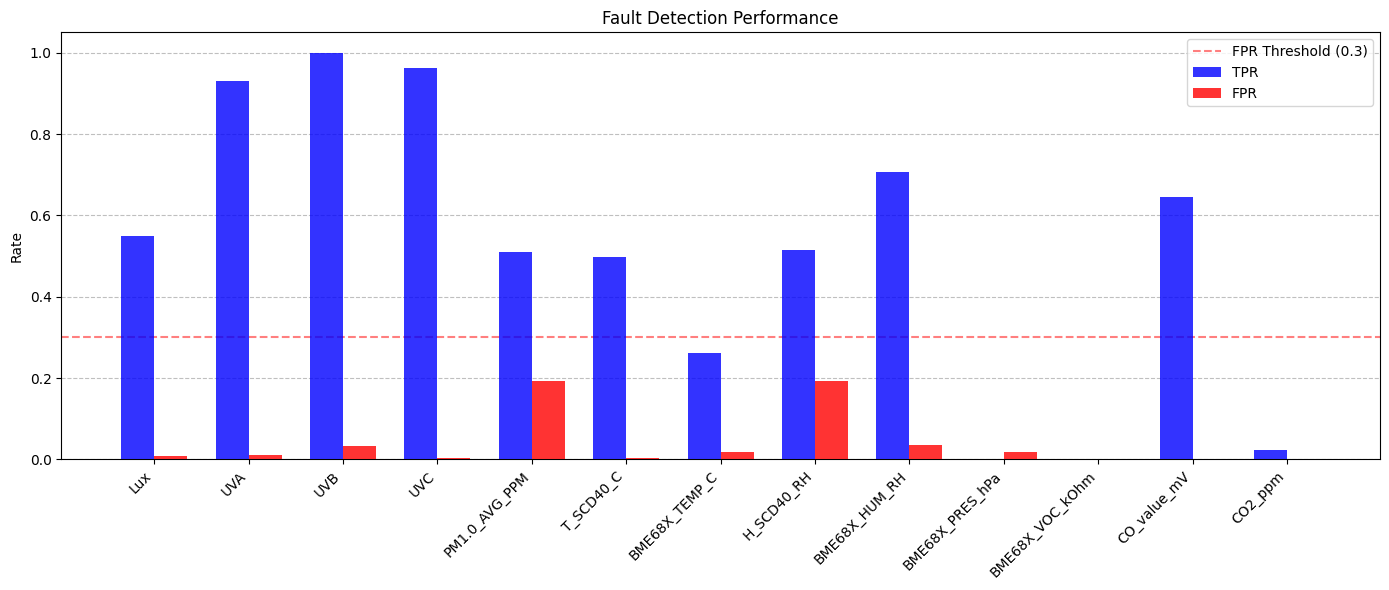

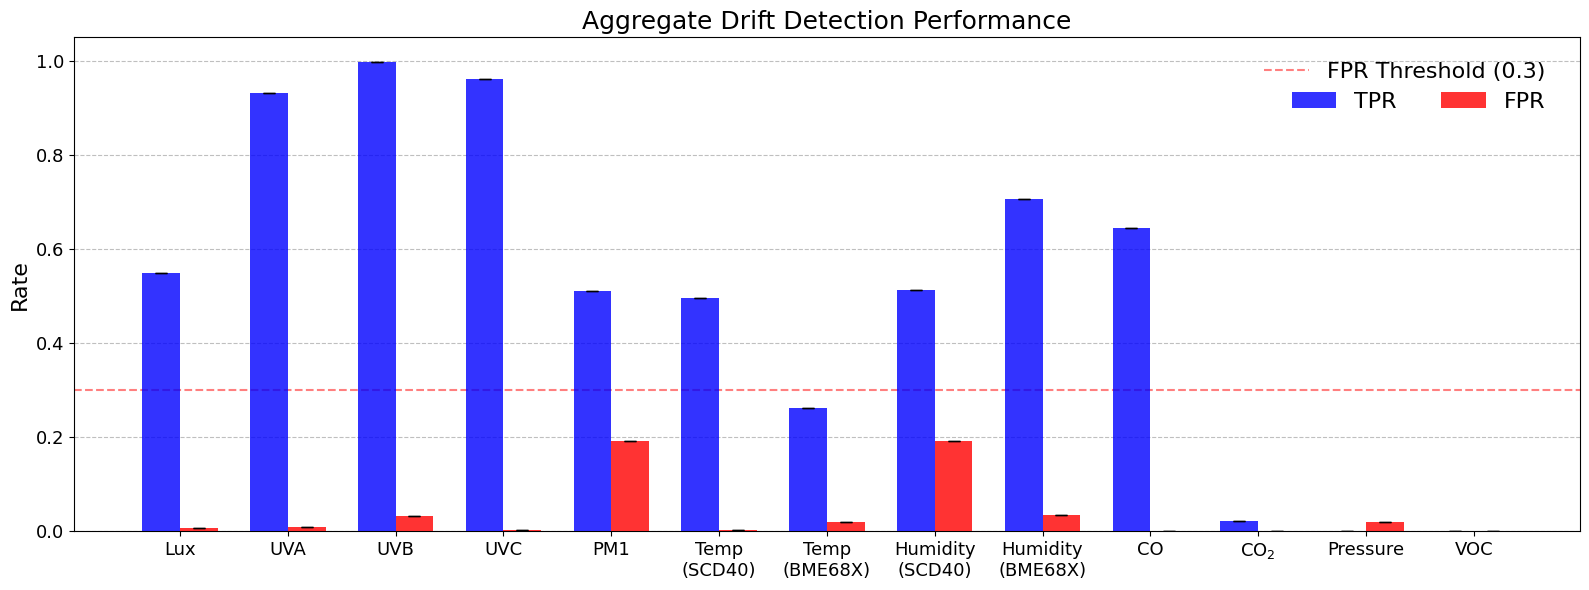

In [10]:
# VISUALIZATION EXAMPLES

# test_drift_amounts = {"Lux": 1000, "UVA": 50, "UVB": 4, "UVC": 4, "PM1.0_AVG_PPM": 20, "T_SCD40_C": 10, "BME68X_TEMP_C": 10, "H_SCD40_RH": 20, "BME68X_HUM_RH": 20, "BME68X_PRES_hPa": 10, "BME68X_VOC_kOhm": 80, "CO_value_mV": 10, "CO2_ppm": 500}
# test_drift_amounts = {"Lux": 1000, "UVA": 50, "UVB": 4, "UVC": 4, "PM1.0_AVG_PPM": 20, "T_SCD40_C": 10, "BME68X_TEMP_C": 10, "H_SCD40_RH": 20, "BME68X_HUM_RH": 20, "BME68X_PRES_hPa": 10, "BME68X_VOC_kOhm": 80, "CO2_ppm": 200}
# test_drift_amounts = {"CO2_ppm": 200}
plot_systemwide_results(drift_amount=drift_amounts)

# Current device: TPR/FPR performance with a separate self-fault per target.
# systemwide_self_fault = plot_systemwide_results()

# Current device: TPR/FPR response of all targets to one selected faulty sensor.
# systemwide_cross_fault = plot_systemwide_results("UVB")

# Aggregate all device results currently collected in drift_results_manager.
aggregate_self_fault = plot_systemwide_aggregate_results()

# Aggregate a fixed cross-fault across devices
# aggregate_cross_fault = plot_systemwide_aggregate_results("UVB")

# Healthy/faulty time series for any target/fault combination
# plot_target_timeseries("PM1.0_AVG_PPM", "PM1.0_AVG_PPM", 20)
# plot_diagnostic_results("CO2_ppm", "CO2_ppm", 200)

# Final ensemble flag and individual statistical-test flags for CO2_ppmny target/fault combination
# flag_result = plot_detector_flags("PM1.0_AVG_PPM", "PM1.0_AVG_PPM", 10)

In [11]:
# export_diagnostic_csv("PM1.0_AVG_PPM", "PM1.0_AVG_PPM", 5, "../other/PM1_residuals.csv")
# export_induced_drift_csvs()

In [12]:
# REVIEW AND SAVE ALL RESULTS
# drift_results_manager.metrics_df[drift_results_manager.metrics_df['Target'] == 'UVB']

# Save results
# drift_results_manager.save(results_manager_path)
# print(f"Saved {len(drift_results_manager.metrics_df)} rows to {results_manager_path}")